# Finding the Thermal Diffusivity of Soil from Buried Temperature Sensors
### The 1D heat equation with a Physics-Informed Neural Network: NumPy from scratch (Part A) and PyTorch (Part B)

Push a thermometer a few centimetres into the ground and log it for a few days. The reading swings up and down once a day, following the sun. Push a second one in deeper and its swings are smaller and arrive later. Push a third one deeper still and the daily rhythm is almost gone. The soil is acting like a filter: it passes the daily temperature wave downwards, but weakens it and delays it as it goes.

How much it weakens and delays the wave depends on one number, the **thermal diffusivity** of the soil, which says how quickly heat spreads through it. Wet clay, dry sand and frozen ground differ a lot. Farmers use it to judge seed-bed temperatures, engineers use it to bury cables and pipes, and heat-pump designers use it to size ground loops. And it is exactly what a few cheap temperature sensors can tell us.

In this notebook we do three things:

1. **We work out the physics.** The temperature in the ground obeys the **heat equation**, and for a daily cycle it has an exact solution: a *damped wave* that fades with depth and lags with depth. It is the same "decaying cosine" shape as the damped oscillator from the second notebook of this series, but spread over depth instead of time.
2. **We compare ways of reading the sensors.** The classical methods compare amplitudes and delays between depths. We then train a neural network that uses the heat equation itself to fit all the readings at once and to find the diffusivity.
3. **We watch the network learn.** A video shows a network that sees only the sensor readings next to one that also knows the heat equation.

This is the first project in the PDE (partial differential equation) series. Compared with the ODE projects there are three new things:

* **The unknown depends on two variables**, depth and time, so the network has two inputs.
* **There are many more places to check the equation**: a whole depth–time map, not just a line.
* **The equation has a second derivative in space and a first derivative in time**, so we need the network's derivatives in two different directions.

**What you will find here**

| Section | What it covers |
|---|---|
| **Background** | Where the heat equation comes from, the exact solution for a daily cycle (fully derived), the classical sensor methods, what the daily swing says about "thermal inertia", sudden heating of a heat-shield tile, a heat-budget check, and how the loss is built for a PDE |
| **Setup** | Constants, the exact solution, a classical finite-difference solver, an interactive explorer, synthetic sensor readings, the classical estimators, and the video helpers |
| **Part A** | NumPy only: a network that returns its own time and depth derivatives, hand-derived gradients, a gradient check, Adam, data-only vs physics-informed training, the diffusivity estimate, a heat-budget check, a training video and GIF, and a "cloudy afternoon" test with a messy surface temperature |
| **Part B** | PyTorch with automatic differentiation, then L-BFGS, `torch.func`, and a study of how many sensors you really need |

**Requirements:** Python 3.9+, `numpy`, `scipy`, `matplotlib`, `pillow`. Optional: `ipywidgets` (sliders), `ffmpeg` (MP4 files), `torch` (Part B).

---
# Background

## 1. Where this equation shows up

The heat equation describes how temperature spreads by conduction (heat moving through a material without the material itself moving). The same equation, with different names for the symbols, covers:

* **Soil and rock temperature.** Daily and yearly temperature waves in the ground, frost depth, permafrost.
* **Ground-source heat pumps and buried cables and pipes.** How deep is "deep enough" to escape the daily swing.
* **Building walls and roofs.** Why a thick stone wall stays cool through a hot afternoon.
* **Thermal protection of spacecraft.** An insulating tile on a re-entry vehicle is heated on one side for minutes while the other side must stay cool.
* **Remote sensing.** A satellite sees only the temperature of the surface. How much that surface heats up by day and cools by night depends on how easily heat flows into the ground below, a property called *thermal inertia*. Day–night temperature differences are used to map it (Price, 1977).

## 2. Deriving the heat equation

Think of a vertical column of soil with $z$ measured **downwards** from the surface, and $T(z,t)$ the temperature at depth $z$ and time $t$. We assume the soil is the same in every horizontal direction (so only depth matters), that heat moves only by conduction, and that there are no heat sources inside it (no chemical reactions, no moving water).

**Energy balance on a thin slice.** Take a slice between depths $z$ and $z+\Delta z$ with unit area. Let $q(z,t)$ be the heat flow downwards (power per area, W/m²). Over a short time $\Delta t$:

> (heat stored in the slice) = (heat flowing in at the top) − (heat flowing out at the bottom)

The heat stored depends on how much the temperature rises. If the soil has density $\rho$ and specific heat $c$, then $\rho c$ is the heat needed to raise one cubic metre by one degree, so
$$
\rho c\,\Delta z\,\frac{\partial T}{\partial t}\,\Delta t=\big[q(z,t)-q(z+\Delta z,t)\big]\Delta t .
$$
Divide by $\Delta z\,\Delta t$ and let both shrink to zero. The difference quotient of $q$ becomes a derivative:
$$
\rho c\,\frac{\partial T}{\partial t}=-\frac{\partial q}{\partial z}.
\tag{1}
$$

**Fourier's law.** Heat flows from warm to cold, in proportion to how steeply the temperature changes:
$$
q=-k\,\frac{\partial T}{\partial z},
\tag{2}
$$
where $k$ (W/m/K) is the thermal conductivity. The minus sign says heat flows towards lower temperature.

**Putting (1) and (2) together** with constant $k$:
$$
\rho c\,\frac{\partial T}{\partial t}=k\,\frac{\partial^{2}T}{\partial z^{2}}
\quad\Longrightarrow\quad
\boxed{\,\frac{\partial T}{\partial t}=\alpha\,\frac{\partial^{2}T}{\partial z^{2}},\qquad \alpha=\frac{k}{\rho c}\,}
\tag{3}
$$
The number $\alpha$ is the **thermal diffusivity**. Its unit is m²/s (we will use m²/day, which suits a daily cycle). Typical soils have $\alpha$ somewhere around a few times $10^{-7}$ m²/s: it is higher for wet or compact soil and lower for dry, loose soil. Our test soil has $\alpha=5\times10^{-7}$ m²/s, which is $0.0432$ m²/day.

**What kind of equation is this?** It is first-order in time and second-order in space. So, in the spirit of the ODE projects, it needs conditions to pick one solution: an **initial condition** (the temperature profile at the start) and **two boundary conditions** (what happens at the top and at the bottom of the domain).

**Diffusion forgets.** Equation (3) smooths things out. Sharp temperature differences fade, and details of the starting profile are slowly lost. A rough distance that heat travels in time $t$ is the diffusion length $\sqrt{\alpha t}$. For our soil, after one day this is about $\sqrt{0.0432}\approx0.21$ m. This is why the deep soil barely notices the weather on the surface.

## 3. The exact solution for a daily temperature cycle

Suppose the surface temperature follows a clean daily cycle with mean $T_{\text{mean}}$, swing $A$ and angular frequency $\omega=2\pi/(1\text{ day})$:
$$
T(0,t)=T_{\text{mean}}+A\cos\omega t .
$$
Because (3) is linear, we can subtract the mean. Define the temperature **anomaly** $\theta=(T-T_{\text{mean}})$, which obeys the same equation with $\theta(0,t)=A\cos\omega t$ and $\theta\to0$ deep down.

**Step 1: a complex trick.** Write the cosine as the real part of a complex exponential, $A\cos\omega t=\operatorname{Re}\big[A e^{i\omega t}\big]$, and look for a solution of the form
$$
\theta(z,t)=\operatorname{Re}\big[F(z)\,e^{i\omega t}\big].
$$
Since $\partial_t$ acts on $e^{i\omega t}$ to give $i\omega$, equation (3) becomes an ODE for $F$:
$$
i\omega\,F=\alpha\,F''
\quad\Longrightarrow\quad
F''=\frac{i\omega}{\alpha}\,F .
$$

**Step 2: solve it like the oscillator.** Try $F=e^{-kz}$. Then $k^2=i\omega/\alpha$. Using $\sqrt i=(1+i)/\sqrt2$,
$$
k=\sqrt{\frac{i\omega}{\alpha}}=(1+i)\sqrt{\frac{\omega}{2\alpha}}=\frac{1+i}{d},
\qquad
\boxed{\,d=\sqrt{\frac{2\alpha}{\omega}}\,}
$$
The number $d$ is the **damping depth**. (There is also a root $e^{+kz}$, but it grows without limit with depth, so we discard it.) With the surface condition $F(0)=A$:
$$
F(z)=A\,e^{-(1+i)z/d}=A\,e^{-z/d}\,e^{-iz/d}.
$$

**Step 3: take the real part.**
$$
\boxed{\,\theta(z,t)=A\,e^{-z/d}\cos\!\Big(\omega t-\frac zd\Big)\,}
\tag{4}
$$

**Check by substitution.** Let $\varphi=\omega t-z/d$, so $\theta=Ae^{-z/d}\cos\varphi$, with $\partial\varphi/\partial t=\omega$ and $\partial\varphi/\partial z=-1/d$. Then
$$
\theta_t=-A\omega\,e^{-z/d}\sin\varphi,\qquad
\theta_z=\frac Ad\,e^{-z/d}\big(\sin\varphi-\cos\varphi\big),
$$
$$
\theta_{zz}=\frac Ad\,e^{-z/d}\Big[-\frac1d(\sin\varphi-\cos\varphi)-\frac1d(\cos\varphi+\sin\varphi)\Big]=-\frac{2A}{d^{2}}\,e^{-z/d}\sin\varphi .
$$
Since $2\alpha/d^{2}=\omega$, we get $\alpha\theta_{zz}=-A\omega e^{-z/d}\sin\varphi=\theta_t$, so (3) holds.

**What formula (4) says.**

| Feature | Formula | For our soil ($d=11.7$ cm) |
|---|---|---|
| Amplitude at depth $z$ | $A\,e^{-z/d}$ | 65% at 5 cm, 18% at 20 cm, 8% at 30 cm |
| Time delay at depth $z$ | $\dfrac{z}{d\,\omega}$ | 1.6 hours at 5 cm, 9.8 hours at 30 cm |
| Speed of the wave | $\omega d=\sqrt{2\alpha\omega}$ | about 3 cm per hour |
| Wavelength | $2\pi d$ | about 74 cm |
| Depth where the swing is reversed | $\pi d$ | about 37 cm (the soil is coolest when the surface is warmest, and the swing is only 4% of the surface swing) |

**A link to the damped oscillator.** The oscillator solution was $e^{-\alpha t}\cos(\omega_d t)$: a cosine inside a decaying exponential, coming from a pair of complex roots of a characteristic equation. Formula (4) has the same shape, $e^{-z/d}\cos(\omega t-z/d)$, and it also comes from a complex root, $k=(1+i)/d$. The difference is that the decay and the wiggle now happen in **depth** instead of time, and the oscillation is forced at the surface. Nature builds a damped wave out of an equation that has no wave in it. Heat does not "propagate" like a sound wave. This wave is a pattern in the way diffusion reacts to a repeating input.

## 4. Reading the sensors: the classical methods

Suppose sensors at depths $z_1,z_2,\dots$ record the temperature. Fit a single daily cosine to each record, $\theta_i(t)\approx a_i\cos\omega t+b_i\sin\omega t$. Its **amplitude** is $A_i=\sqrt{a_i^2+b_i^2}$ and its **phase lag** is $\varphi_i=\operatorname{atan2}(b_i,a_i)$, so $\theta_i\approx A_i\cos(\omega t-\varphi_i)$. Compare with (4):
$$
\ln A_i=\ln A-\frac{z_i}{d},\qquad \varphi_i=\frac{z_i}{d}.
$$
Both are straight lines in depth. The slope of the first is $-1/d$, and the slope of the second is $+1/d$. Once we have $d$, the diffusivity follows from $d=\sqrt{2\alpha/\omega}$:
$$
\boxed{\,\alpha=\frac{\omega\,d^{2}}{2}\,}
$$
For **two** sensors at depths $z_1$ and $z_2$ this gives the two classical estimates:
$$
\alpha_{\text{amp}}=\frac{\omega\,(z_2-z_1)^2}{2\,\big[\ln(A_1/A_2)\big]^2},\qquad
\alpha_{\text{phase}}=\frac{\omega\,(z_2-z_1)^2}{2\,(\varphi_2-\varphi_1)^2}.
$$
These are the amplitude method and the phase method of soil physics (Horton et al., 1983). They are simple and need no computer. Their weak points:

* They throw away most of the record. Everything is squeezed into one amplitude and one phase per sensor.
* Deep sensors have small amplitudes, so noise matters most exactly where $\ln A$ is most sensitive.
* They need the surface temperature to be a clean cosine, and the record to be a whole number of days.
* In real soil, the two answers often disagree because water moves or the soil changes with depth. The disagreement itself is a useful warning sign.

## 5. What the daily swing says about thermal inertia

How much heat enters the ground? Use Fourier's law (2) with formula (4). At the surface $\varphi=\omega t$, so $\theta_z(0,t)=\frac Ad(\sin\omega t-\cos\omega t)$ and the heat flow into the ground is
$$
q(0,t)=-k\,\theta_z(0,t)=\frac{kA}{d}(\cos\omega t-\sin\omega t)=\frac{\sqrt2\,kA}{d}\cos\!\Big(\omega t+\frac\pi4\Big).
$$
Two things follow.

* **The heat flow into the ground peaks 45° ahead of the surface temperature**, which for a daily cycle is 3 hours earlier. The ground starts storing heat before the surface reaches its warmest.
* **The amplitude of the heat flow is $\sqrt2kA/d$.** Since $\sqrt2/d=\sqrt{\omega/\alpha}$ and $k/\sqrt\alpha=\sqrt{k\rho c}$,
$$
q_{\text{amp}}=A\,\sqrt{\omega}\,\sqrt{k\rho c}
\quad\Longrightarrow\quad
I\equiv\sqrt{k\rho c}=\frac{q_{\text{amp}}}{A\sqrt\omega}.
$$
The quantity $I$ is the **thermal inertia**. For the same daily heat input $q_{\text{amp}}$ (set by the sun), the surface swing is $A=q_{\text{amp}}/(I\sqrt\omega)$. So a high-inertia surface (wet soil, rock) swings less than a low-inertia one (dry sand), and that difference is what a satellite sees from orbit. Note that it is $k\rho c$ that matters here, not $\alpha=k/(\rho c)$. The buried sensors in this notebook give $\alpha$. To get $I$ as well, you also need $\rho c$ (for example from the soil's water content).

## 6. A different situation: sudden heating of a heat-shield tile

The daily cycle is one case. Another is a surface whose temperature jumps and then stays put, as at the hot face of a heat-shield tile. Take a slab that starts at $\theta=0$, with $\theta=1$ held at the surface from $t=0$ onwards, and a slab thick enough that the far side is never reached.

**A similarity variable** (the same trick as in the Blasius notebook). There is no length in this problem except the one that diffusion creates, $\sqrt{\alpha t}$, so look for a solution that depends only on
$$
\eta=\frac{z}{2\sqrt{\alpha t}},\qquad \theta(z,t)=f(\eta).
$$
The chain rule gives $\eta_t=-\eta/(2t)$ and $\eta_z=1/(2\sqrt{\alpha t})$, so
$$
\theta_t=-\frac{\eta}{2t}f',\qquad
\theta_z=\frac{f'}{2\sqrt{\alpha t}},\qquad
\theta_{zz}=\frac{f''}{4\alpha t}.
$$
Putting these into $\theta_t=\alpha\theta_{zz}$ makes every $t$ cancel and leaves an ODE:
$$
-\frac{\eta}{2t}f'=\frac{f''}{4t}
\quad\Longrightarrow\quad
f''=-2\eta f' .
$$
This is first-order in $f'$: $f'=Ce^{-\eta^{2}}$. The conditions are $f(0)=1$ (hot surface) and $f(\infty)=0$ (nothing has arrived far away). Integrating from $\eta$ to $\infty$ gives $f(\eta)=-C\int_\eta^\infty e^{-s^2}ds$, and $f(0)=1$ fixes $C=-2/\sqrt\pi$. The result is
$$
\boxed{\,\theta(z,t)=\operatorname{erfc}\!\Big(\frac{z}{2\sqrt{\alpha t}}\Big)\,}
\tag{5}
$$
where $\operatorname{erfc}(\eta)=\frac2{\sqrt\pi}\int_\eta^\infty e^{-s^2}ds$ is the complementary error function. Two useful facts:

* The heated layer is about $z\approx3.6\sqrt{\alpha t}$ deep (that is where $\operatorname{erfc}$ falls to 1%). It grows like $\sqrt t$.
* The heat flow into the solid at the surface is $q=-k\theta_z(0,t)=\dfrac{k\,\Delta T}{\sqrt{\pi\alpha t}}$, because $f'(0)=-2/\sqrt\pi$. It is huge at first and falls off like $1/\sqrt t$.

For an illustrative insulating tile with $\alpha=5\times10^{-7}$ m²/s, ten minutes of heating warms only the outer $3.6\sqrt{5\times10^{-7}\cdot600}\approx6$ cm. We plot this in the Setup section. The same sensor idea works here too: thermocouples buried in a tile tell you $\alpha$.

## 7. A heat-budget check that needs no exact answer

Integrate the heat equation over the depth of the domain, $0\le z\le L$:
$$
\frac{d}{dt}\int_0^L\theta\,dz=\int_0^L\alpha\,\theta_{zz}\,dz=\alpha\,\big[\theta_z(L,t)-\theta_z(0,t)\big].
\tag{6}
$$
The left side is the rate at which the soil column stores heat. The right side is the heat flowing in at the top minus the heat flowing out at the bottom (times $\rho c$). This balance holds for **any** correct solution. So we can test a model's temperature field against (6) without knowing the true answer, in the same spirit as the energy check of the oscillator notebook and the momentum check of the Blasius notebook.

## 8. A classical solver for comparison: Crank–Nicolson

To know the right answer when the surface temperature is *not* a clean cosine, we need a classical numerical solver. We use the **Crank–Nicolson** scheme (Crank and Nicolson, 1947). Put the soil on a grid of depths $z_j=j\,\Delta z$ and step in time by $\Delta t$. Write $L\theta_j=(\theta_{j+1}-2\theta_j+\theta_{j-1})/\Delta z^2$ for the three-point second difference. Evaluate the right side of the heat equation as the **average** of the old and new time levels:
$$
\frac{\theta_j^{n+1}-\theta_j^{n}}{\Delta t}=\frac\alpha2\Big[L\theta_j^{n+1}+L\theta_j^{n}\Big].
$$
This is stable for any step size and accurate to second order in both $\Delta z$ and $\Delta t$. At each step it gives a tridiagonal system of equations for the new temperatures, which a standard solver handles quickly. We check it against formula (4) in the Setup section.

## 9. The PINN for the heat equation

The network $\hat\theta_\Theta(z,t)$ takes depth and time and returns the temperature anomaly. (We write $\Theta$ for the network's weights, to keep $\theta$ for temperature.) We can differentiate it in either direction, which gives $\hat\theta_t$, $\hat\theta_z$ and $\hat\theta_{zz}$. We work with the anomaly in units of the surface swing $A$, so the numbers are of order one. The loss has four parts:

**Sensor loss.** The mean squared difference between the network and the $N_d$ readings:
$$
\mathcal L_{\text{data}}=\frac1{N_d}\sum_i\big(\hat\theta(z_i,t_i)-\theta_i\big)^2 .
$$

**Equation loss.** At $N_c$ points $(z_j,t_j)$ spread over the whole depth–time rectangle (not only at sensors), form the residual of (3), scaled by $\omega$ so it is of order one:
$$
r_j=\frac{\hat\theta_t-\alpha\,\hat\theta_{zz}}{\omega}\Big|_{(z_j,t_j)},\qquad
\mathcal L_{\text{PDE}}=\frac1{N_c}\sum_j r_j^2 .
$$

**Surface and deep-boundary losses.** At the top, the network must match the recorded surface temperature $\theta_s(t)$. At the bottom of the model ($z=L$) the temperature is the steady deep value:
$$
\mathcal L_{\text{BC}}=\frac1{N_b}\sum_k\Big[\hat\theta(0,t_k)-\theta_s(t_k)\Big]^2+\frac1{N_b}\sum_k\hat\theta(L,t_k)^2 .
$$
(Taking the deep temperature as constant at $L=0.6$ m is an approximation: the real daily swing at that depth is a few hundredths of a degree.)

**There is no initial-condition term.** We do not know the temperature profile at the start. The sensors, the surface record and the equation together settle it, because the effect of the starting profile fades, as explained in section 2.

**Total loss:** $\mathcal L=\lambda_{\text{data}}\mathcal L_{\text{data}}+\lambda_{\text{PDE}}\mathcal L_{\text{PDE}}+\lambda_{\text{BC}}\mathcal L_{\text{BC}}$. Setting $\lambda_{\text{PDE}}=\lambda_{\text{BC}}=0$ gives the "sensors only" network we compare against.

**The unknown diffusivity.** In the inverse problem $\alpha$ is not known, so it becomes one more trainable number. A diffusivity must be positive, so we train its logarithm $s$ and use $\alpha=e^{s}$. The gradient follows from the chain rule. The residual depends on $\alpha$ through $-\alpha\hat\theta_{zz}/\omega$, so
$$
\frac{\partial\mathcal L_{\text{PDE}}}{\partial\alpha}=\frac1{N_c}\sum_j2\,r_j\Big(-\frac{\hat\theta_{zz}}{\omega}\Big),\qquad
\frac{\partial\mathcal L}{\partial s}=\lambda_{\text{PDE}}\,\alpha\,\frac{\partial\mathcal L_{\text{PDE}}}{\partial\alpha}.
$$

**What the sensors must supply.** With the surface temperature known, even one interior sensor carries the information (its amplitude and delay relative to the surface). More sensors add accuracy and a way to see whether the soil really behaves like uniform soil.

## 10. Differentiating the network in two directions

The network has two inputs, depth and time. We carry four quantities through every layer: the value, the depth-derivative $\partial_z$, the second depth-derivative $\partial_z^2$, and the time-derivative $\partial_t$. (No mixed derivative appears in equation (3), so we do not need one.) Write them with subscripts, $\mathbf P,\mathbf P_z,\mathbf P_{zz},\mathbf P_t$ for what enters a layer.

* **Linear step.** $\mathbf Z=\mathbf P\mathbf W+\mathbf b$, and the derivatives pass straight through: $\mathbf Z_z=\mathbf P_z\mathbf W$, $\mathbf Z_{zz}=\mathbf P_{zz}\mathbf W$, $\mathbf Z_t=\mathbf P_t\mathbf W$.
* **Activation step.** With $\mathbf A=\tanh\mathbf Z$ and $\mathbf S=1-\mathbf A^2$:
$$
\mathbf A_z=\mathbf S\,\mathbf Z_z,\qquad
\mathbf A_{zz}=\mathbf S\,\mathbf Z_{zz}-2\mathbf A\mathbf S\,\mathbf Z_z^{2},\qquad
\mathbf A_t=\mathbf S\,\mathbf Z_t .
$$
The second one is the product rule applied to $\mathbf A_z$, using $\partial_z\mathbf S=-2\mathbf A\mathbf S\mathbf Z_z$. It is the same formula as in the oscillator notebook.
* **Start of the chain.** The input has two columns, $(\bar z,\bar t)$. We feed the network scaled coordinates $\bar z=z/L$ and $\bar t=t/t_{\max}$, so the numbers it sees are of order one. We want derivatives with respect to the **physical** $z$ and $t$, so we simply start the chain with the right seeds: $\mathbf P_z=(1/L,\,0)$, $\mathbf P_t=(0,\,1/t_{\max})$ and $\mathbf P_{zz}=0$. The chain rule is then built in, and no later step needs to know about the scaling.

Part A codes this by hand. Part B lets PyTorch do it.

## 11. What to expect from this PINN

* **It is not magic.** If the exact solution is known and the surface is a clean cosine, a least-squares fit of formula (4) to the sensor data is already the best possible estimate. We will see that the network matches it but does not beat it. The network earns its keep when there is no formula: a messy surface temperature, an unknown starting profile, or conditions that no one has solved by hand.
* **Time moves one way.** Heat equation solutions at later times depend on earlier ones. PINNs that ignore this can fail on harder problems (Wang et al., 2022). Here the problem is gentle, and training works without special measures.
* **Sensors only vs sensors + physics.** A network trained on the sensors alone has nothing to say about depths without sensors, such as the top 5 cm or the soil below 30 cm. The physics-informed network gets those regions from the equation and the boundary conditions.

---
# Setup (shared by both parts)

The cells in this section define the constants, the exact solution, a classical solver, an interactive explorer, the synthetic sensor readings, the classical estimators, and the helpers for plotting and for the training video. Only NumPy, SciPy and Matplotlib are used. Run them once, then go to Part A or Part B.

## S1. Imports

In [1]:
import os
import time
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.linalg import solve_banded
from scipy.optimize import minimize_scalar
from scipy.special import erfc
from scipy.interpolate import RegularGridInterpolator

# a folder for the video and the GIF
MEDIA_DIR = Path("media")
MEDIA_DIR.mkdir(exist_ok=True)

## S2. Constants
Depth is in metres, time in **days**, and the diffusivity in m²/day. The soil has $\alpha=5\times10^{-7}$ m²/s, which is $0.0432$ m²/day. The surface swings by $\pm8$ °C around 15 °C once per day. The model covers the top 0.6 m for three days.

In [2]:
# the soil and the daily cycle
ALPHA_TRUE = 5.0e-7 * 86400.0        # thermal diffusivity: 5e-7 m^2/s expressed in m^2/day (= 0.0432)
OMEGA = 2.0 * np.pi                  # one cycle per day (rad/day)
T_MEAN, AMP = 15.0, 8.0              # mean temperature and surface swing (deg C)

# the part of the world we model
Z_MAX, T_MAX = 0.6, 3.0              # 0 to 0.6 m deep, 0 to 3 days

# derived quantities
def damping_depth(alpha, omega=OMEGA):
    return np.sqrt(2.0 * alpha / omega)

d_true = damping_depth(ALPHA_TRUE)
print(f"alpha = {ALPHA_TRUE:.4f} m^2/day  ({ALPHA_TRUE/86400:.1e} m^2/s)")
print(f"damping depth d = {100*d_true:.1f} cm")
print(f"time delay at 5 cm / 30 cm = {24*0.05/(d_true*OMEGA):.1f} h / {24*0.30/(d_true*OMEGA):.1f} h")
print(f"wave speed = {100*OMEGA*d_true/24:.1f} cm per hour,  wavelength = {100*2*np.pi*d_true:.0f} cm")

alpha = 0.0432 m^2/day  (5.0e-07 m^2/s)
damping depth d = 11.7 cm
time delay at 5 cm / 30 cm = 1.6 h / 9.8 h
wave speed = 3.1 cm per hour,  wavelength = 74 cm


## S3. The exact solution for a daily cycle (formula 4)
The function gives the temperature **anomaly in units of the surface swing**, $\theta/A=e^{-z/d}\cos(\omega t-z/d)$. Multiply by `AMP` and add `T_MEAN` for degrees Celsius.

In [3]:
def exact_theta(z, t, alpha=ALPHA_TRUE):
    # temperature anomaly in units of the surface swing: formula (4) with A = 1
    d = damping_depth(alpha)
    return np.exp(-z / d) * np.cos(OMEGA * t - z / d)


def to_celsius(theta):
    return T_MEAN + AMP * np.asarray(theta)

## S4. A classical solver (Crank–Nicolson, background section 8)
`fd_solve` steps the heat equation forward in time on a grid of depths, for **any** surface temperature `surf(t)` and any starting profile. It returns the whole depth–time field. We test it against the exact solution first: start from formula (4), force the surface with the same cosine, and compare after three days. The solver uses a tall domain here (1.5 m) so the deep boundary does not matter.

In [4]:
def fd_solve(alpha, surf, z_max, t_end, dz=0.0025, dt=0.002, theta0=None, deep=0.0):
    # Crank-Nicolson solution of theta_t = alpha * theta_zz.
    #   surf(t) : temperature anomaly imposed at z = 0
    #   theta0(z): starting profile (zero if None);  deep: temperature anomaly imposed at z = z_max
    nz = int(round(z_max / dz)) + 1
    z = np.linspace(0.0, z_max, nz)
    nt = int(round(t_end / dt))
    r = alpha * dt / dz**2

    theta = np.zeros(nz) if theta0 is None else np.array(theta0(z), dtype=float)
    theta[0], theta[-1] = surf(0.0), deep

    n = nz - 2                                   # unknown interior points
    band = np.zeros((3, n))                      # tridiagonal matrix in banded form
    band[0, 1:] = -r / 2.0
    band[1, :] = 1.0 + r
    band[2, :-1] = -r / 2.0

    times, field = [0.0], [theta.copy()]
    for step in range(nt):
        t_new = (step + 1) * dt
        rhs = theta[1:-1] + r / 2.0 * (theta[2:] - 2.0 * theta[1:-1] + theta[:-2])
        rhs[0] += r / 2.0 * surf(t_new)
        rhs[-1] += r / 2.0 * deep
        theta[1:-1] = solve_banded((1, 1), band, rhs)
        theta[0], theta[-1] = surf(t_new), deep
        times.append(t_new)
        field.append(theta.copy())
    return z, np.array(times), np.array(field)


z_fd, t_fd, field_fd = fd_solve(ALPHA_TRUE, lambda t: np.cos(OMEGA * t), 1.5, T_MAX,
                                theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
difference = np.abs(field_fd - exact_theta(z_fd[None, :], t_fd[:, None])).max()
print(f"largest difference between the solver and formula (4): {difference:.1e}  (in units of the surface swing)")

largest difference between the solver and formula (4): 2.3e-05  (in units of the surface swing)


The solver and the formula agree to about $2\times10^{-5}$ of the surface swing, so both the solver and our derivation of formula (4) are working.

## S5. The damped wave, in pictures
Left: temperature against time at five depths. The swings shrink and arrive later as we go down. Right: temperature against depth at four times of day. The envelope $\pm Ae^{-z/d}$ (dashed) is the same damped shape as in the oscillator notebook. The dotted lines mark the sensor depths we will use.

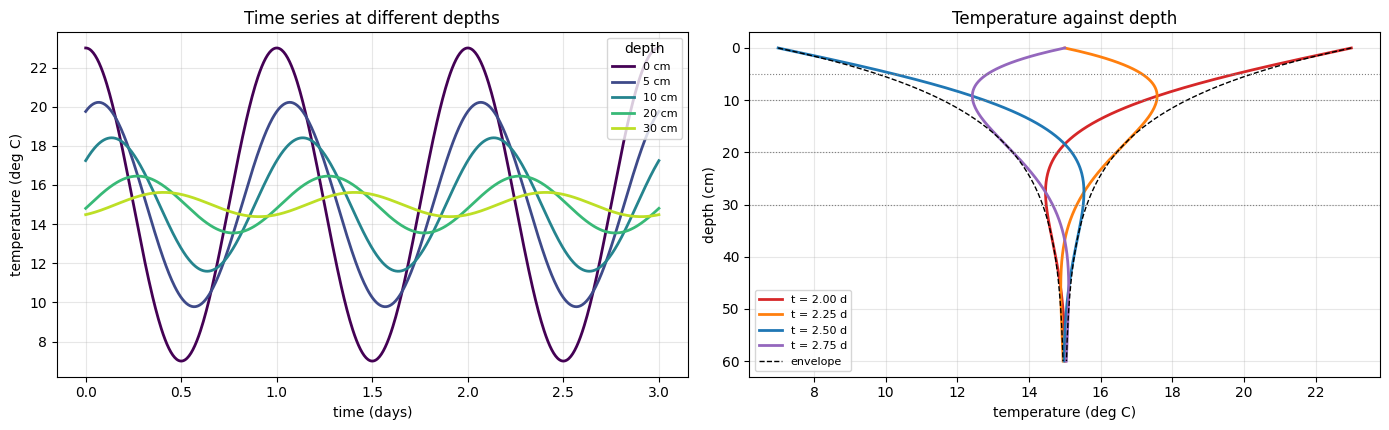

In [5]:
t_fine = np.linspace(0.0, 3.0, 600)
z_fine = np.linspace(0.0, Z_MAX, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for z_cm, colour in zip((0, 5, 10, 20, 30), plt.cm.viridis(np.linspace(0.0, 0.9, 5))):
    axes[0].plot(t_fine, to_celsius(exact_theta(z_cm / 100.0, t_fine)), color=colour, lw=2, label=f"{z_cm} cm")
axes[0].set_xlabel("time (days)")
axes[0].set_ylabel("temperature (deg C)")
axes[0].set_title("Time series at different depths")
axes[0].legend(title="depth", loc="upper right", fontsize=8)
axes[0].grid(alpha=0.3)

for t_day, colour in zip((2.0, 2.25, 2.5, 2.75), ("tab:red", "tab:orange", "tab:blue", "tab:purple")):
    axes[1].plot(to_celsius(exact_theta(z_fine, t_day)), 100 * z_fine, color=colour, lw=2, label=f"t = {t_day:.2f} d")
axes[1].plot(to_celsius(np.exp(-z_fine / d_true)), 100 * z_fine, "k--", lw=1)
axes[1].plot(to_celsius(-np.exp(-z_fine / d_true)), 100 * z_fine, "k--", lw=1, label="envelope")
for z_cm in (5, 10, 20, 30):
    axes[1].axhline(z_cm, color="gray", ls=":", lw=0.8)
axes[1].invert_yaxis()
axes[1].set_xlabel("temperature (deg C)")
axes[1].set_ylabel("depth (cm)")
axes[1].set_title("Temperature against depth")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Try it yourself (Jupyter or Colab).** The sliders change the diffusivity, the surface swing and the sensor depth. Watch how a larger diffusivity lets the wave travel deeper and arrive sooner. If `ipywidgets` is not installed, the cell prints a hint and moves on.

In [6]:
def explore_soil(alpha_1e7=5.0, swing=8.0, sensor_depth_cm=10):
    alpha = alpha_1e7 * 1e-7 * 86400.0                  # m^2/s -> m^2/day
    d = damping_depth(alpha)
    tt = np.linspace(0.0, 3.0, 500)
    zz = np.linspace(0.0, 0.6, 300)
    z_s = sensor_depth_cm / 100.0
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(tt, T_MEAN + swing * np.cos(OMEGA * tt), color="gray", lw=1.5, label="surface")
    axes[0].plot(tt, T_MEAN + swing * exact_theta(z_s, tt, alpha), color="tab:red", lw=2.2,
                 label=f"{sensor_depth_cm} cm deep")
    axes[0].set_ylim(T_MEAN - 9, T_MEAN + 9)
    axes[0].set_xlabel("time (days)")
    axes[0].set_ylabel("temperature (deg C)")
    axes[0].legend(loc="upper right")
    axes[0].grid(alpha=0.3)
    for t_day, colour in zip((2.0, 2.25, 2.5, 2.75), ("tab:red", "tab:orange", "tab:blue", "tab:purple")):
        axes[1].plot(T_MEAN + swing * exact_theta(zz, t_day, alpha), 100 * zz, color=colour, lw=2)
    axes[1].plot(T_MEAN + swing * np.exp(-zz / d), 100 * zz, "k--", lw=1)
    axes[1].plot(T_MEAN - swing * np.exp(-zz / d), 100 * zz, "k--", lw=1)
    axes[1].axhline(sensor_depth_cm, color="tab:red", ls=":")
    axes[1].set_xlim(T_MEAN - 9, T_MEAN + 9)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("temperature (deg C)")
    axes[1].set_ylabel("depth (cm)")
    axes[1].grid(alpha=0.3)
    lag_h = 24 * z_s / (d * OMEGA)
    fig.suptitle(f"alpha = {alpha_1e7:.1f}e-7 m^2/s:  damping depth {100*d:.1f} cm,  "
                 f"amplitude at the sensor {100*np.exp(-z_s/d):.0f}% of the surface,  delay {lag_h:.1f} h")
    plt.tight_layout()
    plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(
        explore_soil,
        alpha_1e7=widgets.FloatSlider(value=5.0, min=1.0, max=15.0, step=0.5, description="alpha (1e-7 m2/s)"),
        swing=widgets.FloatSlider(value=8.0, min=2.0, max=12.0, step=0.5, description="swing (deg C)"),
        sensor_depth_cm=widgets.IntSlider(value=10, min=2, max=40, step=1, description="sensor (cm)"),
    )
except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")

## S6. The heat-shield case (formula 5)
Sudden heating at the surface, from background section 6. The curves are $\operatorname{erfc}\big(z/(2\sqrt{\alpha t})\big)$ at several times, for an illustrative tile with $\alpha=5\times10^{-7}$ m²/s heated for up to ten minutes. The dashed circles are the Crank–Nicolson solution for the same problem (the check on the derivation).

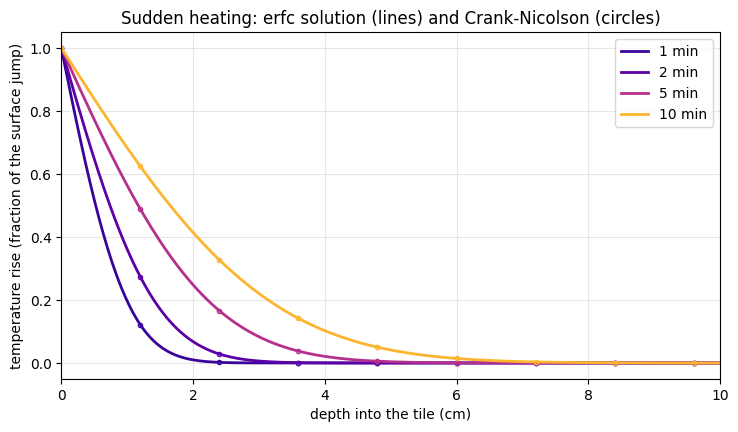

heated depth after 10 minutes, 3.6*sqrt(alpha*t) = 6.2 cm


In [7]:
alpha_tile = 5.0e-7                       # m^2/s (illustrative)
z_tile = np.linspace(0.0, 0.10, 300)      # first 10 cm
minutes = (1, 2, 5, 10)

# the same problem with the classical solver (time in seconds here; the surface jumps to 1 at once)
z_chk, t_chk, f_chk = fd_solve(alpha_tile, lambda t: 1.0, 0.30, 600.0, dz=0.001, dt=0.5)

plt.figure(figsize=(8.5, 4.5))
for m_ in minutes:
    colour = plt.cm.plasma(m_ / 12.0)
    plt.plot(100 * z_tile, erfc(z_tile / (2 * np.sqrt(alpha_tile * 60 * m_))), color=colour, lw=2, label=f"{m_} min")
    k_ = int(round(60 * m_ / 0.5))
    plt.plot(100 * z_chk[::12], f_chk[k_][::12], "o", color=colour, ms=3, mfc="none")
plt.xlabel("depth into the tile (cm)")
plt.ylabel("temperature rise (fraction of the surface jump)")
plt.title("Sudden heating: erfc solution (lines) and Crank-Nicolson (circles)")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 10)
plt.show()
print(f"heated depth after 10 minutes, 3.6*sqrt(alpha*t) = {100*3.6*np.sqrt(alpha_tile*600):.1f} cm")

## S7. The sensor readings
We bury four sensors at **5, 10, 20 and 30 cm**. They log the temperature **every hour for three days**, with random noise of **0.2 °C** (a typical value for a cheap thermistor). The surface temperature comes from a separate record (say an infrared thermometer), which we take as the clean daily cosine. The random seed is fixed so every run gives the same readings. The readings are stored in units of the surface swing, as the network will see them.

292 readings from 4 sensors; noise = 0.2 deg C (0.025 of the surface swing)


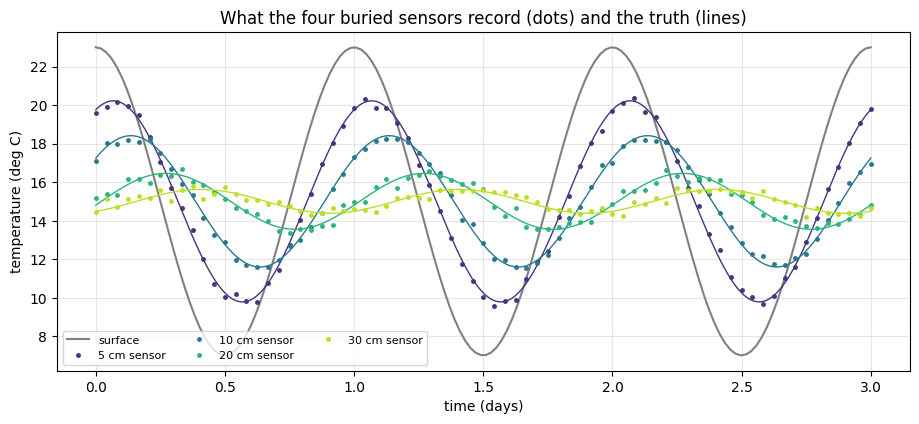

In [8]:
sensor_depths = np.array([0.05, 0.10, 0.20, 0.30])         # metres
sensor_times = np.arange(0.0, T_MAX + 1e-9, 1.0 / 24.0)    # hourly, in days
noise_celsius = 0.2
noise_theta = noise_celsius / AMP

rng_data = np.random.default_rng(5)
theta_clean = exact_theta(sensor_depths[:, None], sensor_times[None, :])           # shape (4, 73)
theta_matrix = theta_clean + noise_theta * rng_data.standard_normal(theta_clean.shape)

# the same readings as a list of points: (depth, time) and the value
zt_data = np.array([(z, t) for z in sensor_depths for t in sensor_times])
theta_data = theta_matrix.reshape(-1, 1)

# surface record: the clean daily cosine, sampled 150 times
t_surface = np.linspace(0.0, T_MAX, 150)
print(f"{len(zt_data)} readings from {len(sensor_depths)} sensors; noise = {noise_celsius} deg C "
      f"({noise_theta:.3f} of the surface swing)")

plt.figure(figsize=(11, 4.4))
plt.plot(t_surface, to_celsius(np.cos(OMEGA * t_surface)), color="gray", lw=1.5, label="surface")
for i, (z, colour) in enumerate(zip(sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    plt.plot(sensor_times, to_celsius(theta_matrix[i]), ".", color=colour, ms=5, label=f"{int(100*z)} cm sensor")
    plt.plot(t_fine, to_celsius(exact_theta(z, t_fine)), "-", color=colour, lw=1)
plt.xlabel("time (days)")
plt.ylabel("temperature (deg C)")
plt.title("What the four buried sensors record (dots) and the truth (lines)")
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## S8. The classical estimators and how well they do
Three ways to turn these readings into a diffusivity, all from background section 4:

* **Amplitude method:** fit a daily cosine to each sensor, then use $\ln A_i=\ln A-z_i/d$. We fit a line through the origin (the surface amplitude is known to be 1 here) by least squares, which uses all four sensors.
* **Phase method:** the same with the delay, $\varphi_i=z_i/d$.
* **Formula fit:** adjust $\alpha$ until formula (4) matches all the readings as closely as possible (least squares). This is the best use of the data when the exact formula applies.

The cell applies them to our readings. Then it repeats the experiment 300 times with fresh random noise, to show how much each method typically wanders.

method                  alpha (m^2/day)    error
amplitude method                0.04140    -4.2%
phase method                    0.04337     0.4%
formula fit                     0.04223    -2.2%
truth                           0.04320



Over 300 repeats with new noise (error in percent):
  amplitude method   mean   0.41%   spread (std)  2.86%   worst  10.4%
  phase method       mean  -0.00%   spread (std)  2.77%   worst   8.1%
  formula fit        mean   0.02%   spread (std)  0.94%   worst   2.6%


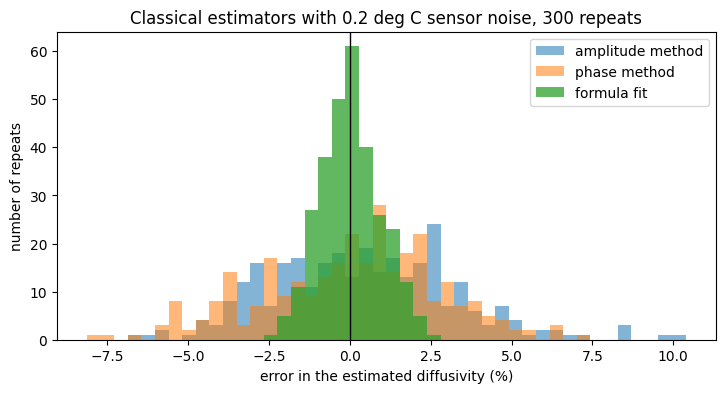

In [9]:
_design = np.column_stack([np.ones_like(sensor_times), np.cos(OMEGA * sensor_times), np.sin(OMEGA * sensor_times)])

def amplitude_and_phase(theta_by_depth):
    # least-squares daily cosine for every sensor record
    coef = np.linalg.lstsq(_design, theta_by_depth.T, rcond=None)[0]      # rows: mean, cos, sin
    return np.hypot(coef[1], coef[2]), np.arctan2(coef[2], coef[1])


def classical_alphas(theta_by_depth, depths=sensor_depths):
    amplitude, phase = amplitude_and_phase(theta_by_depth)
    d_amp = -np.sum(depths**2) / np.sum(depths * np.log(amplitude))       # ln A = -z/d, line through the origin
    d_phase = np.sum(depths**2) / np.sum(depths * phase)                  # phase = z/d
    return OMEGA * d_amp**2 / 2.0, OMEGA * d_phase**2 / 2.0


def formula_fit_alpha(theta_by_depth, depths=sensor_depths):
    misfit = lambda a: np.sum((theta_by_depth - exact_theta(depths[:, None], sensor_times[None, :], a)) ** 2)
    return minimize_scalar(misfit, bounds=(0.005, 0.2), method="bounded", options={"xatol": 1e-9}).x


alpha_amp, alpha_phase = classical_alphas(theta_matrix)
alpha_fit = formula_fit_alpha(theta_matrix)
print(f"{'method':22s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase), ("formula fit", alpha_fit)):
    print(f"{name:22s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':22s}{ALPHA_TRUE:17.5f}")

# 300 repeats with fresh noise
rng_mc = np.random.default_rng(123)
repeats = []
for _ in range(300):
    noisy = theta_clean + noise_theta * rng_mc.standard_normal(theta_clean.shape)
    repeats.append((*classical_alphas(noisy), formula_fit_alpha(noisy)))
repeats = np.array(repeats)
error_pct = 100 * (repeats / ALPHA_TRUE - 1)
print("\nOver 300 repeats with new noise (error in percent):")
for col, name in enumerate(("amplitude method", "phase method", "formula fit")):
    print(f"  {name:18s} mean {error_pct[:, col].mean():6.2f}%   spread (std) {error_pct[:, col].std():5.2f}%   "
          f"worst {np.abs(error_pct[:, col]).max():5.1f}%")

plt.figure(figsize=(8.5, 4))
bins = np.linspace(error_pct.min(), error_pct.max(), 45)
plt.hist(error_pct[:, 0], bins=bins, alpha=0.55, label="amplitude method")
plt.hist(error_pct[:, 1], bins=bins, alpha=0.55, label="phase method")
plt.hist(error_pct[:, 2], bins=bins, alpha=0.75, label="formula fit")
plt.axvline(0, color="k", lw=1)
plt.xlabel("error in the estimated diffusivity (%)")
plt.ylabel("number of repeats")
plt.title("Classical estimators with 0.2 deg C sensor noise, 300 repeats")
plt.legend()
plt.show()

Two things to take away. First, with four sensors and hourly readings, even the simple amplitude and phase methods work, with typical errors around 3%. Second, the formula fit is about three times tighter, because it uses every reading in the way the physics says it should. Keep these numbers in mind: they are what the neural network has to be judged against.

## S9. The evaluation grid and the video helpers

A fixed grid of depths and times is used to compare each network with the exact answer and to draw the animation. Then the helper functions, used by both parts:

* `rmse` measures an error; `make_snapshot_epochs` picks which epochs to record (many early, fewer later).
* `make_training_video` draws a two-column animation: a network that sees **only the sensors** next to a network that also knows **the heat equation**. For each it shows the depth–time temperature map, the temperature profile with depth at one moment (day 2, when the surface is warmest), and a strip with the error and (for the physics network) the diffusivity estimate as training goes on. It writes a GIF with Pillow and an MP4 with `ffmpeg`.
* `convert_mp4_to_gif` turns an MP4 into a GIF. `snapshot_grid` is a still picture of a few moments (it shows on GitHub), and `scrub_epochs` is a slider.

Each "run" is a dictionary with a name, a colour, the saved temperature maps `theta` (one row per snapshot), the saved diffusivity estimates `alpha` (or `None`), and the saved errors `rmse`.

In [10]:
# evaluation grid: 31 depths x 91 times
GRID_Z = np.linspace(0.0, Z_MAX, 31)
GRID_T = np.linspace(0.0, T_MAX, 91)
GRID_ZZ, GRID_TT = np.meshgrid(GRID_Z, GRID_T, indexing="ij")
GRID_POINTS = np.column_stack([GRID_ZZ.ravel(), GRID_TT.ravel()])      # (n, 2): depth, time
GRID_EXACT = exact_theta(GRID_ZZ, GRID_TT).ravel()
PROFILE_TIME = 2.0                                                      # moment shown in the profile panel


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def make_snapshot_epochs(epochs, n_snapshots=90):
    # epoch 0 plus a geometric spread up to the final epoch
    spread = np.unique(np.round(np.geomspace(1, epochs, n_snapshots)).astype(int))
    return sorted(set([0] + spread.tolist()))


def find_ffmpeg():
    path = shutil.which("ffmpeg")
    if path:
        return path
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None

In [11]:
def make_training_video(epochs_saved, runs, mp4_path=None, gif_path=None, fps=12, hold_frames=18,
                        mp4_dpi=90, gif_dpi=60):
    # runs: two dictionaries with keys "name", "color", "theta" (n_snap x n_grid), "alpha" (n_snap or None), "rmse" (n_snap)
    epochs_saved = np.asarray(epochs_saved)
    nz, nt = len(GRID_Z), len(GRID_T)
    i_profile = int(np.argmin(np.abs(GRID_T - PROFILE_TIME)))
    exact_profile = to_celsius(GRID_EXACT.reshape(nz, nt)[:, i_profile])
    sensor_at_profile = int(np.argmin(np.abs(sensor_times - PROFILE_TIME)))

    fig = plt.figure(figsize=(12, 7.2))                  # even pixel sizes, needed for MP4
    gs = fig.add_gridspec(3, 3, height_ratios=[1.5, 1.7, 1.2], width_ratios=[1, 1, 0.04])
    ax_map = [fig.add_subplot(gs[0, j]) for j in range(2)]
    ax_cbar = fig.add_subplot(gs[0, 2])
    ax_prof = [fig.add_subplot(gs[1, j]) for j in range(2)]
    ax_err = fig.add_subplot(gs[2, 0])
    ax_alpha = fig.add_subplot(gs[2, 1])

    images, lines = [], []
    for j, run in enumerate(runs):
        ax = ax_map[j]
        image = ax.imshow(np.zeros((nz, nt)), aspect="auto", origin="upper", cmap="coolwarm", vmin=T_MEAN - AMP,
                          vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
        for z in sensor_depths:
            ax.axhline(100 * z, color="k", lw=0.6, ls=":")
        ax.set_title(run["name"], fontsize=12)
        ax.set_ylabel("depth (cm)")
        ax.set_xlabel("time (days)")
        images.append(image)

        axp = ax_prof[j]
        axp.plot(exact_profile, 100 * GRID_Z, "k--", lw=1.3, label="exact")
        axp.scatter(to_celsius(theta_matrix[:, sensor_at_profile]), 100 * sensor_depths, color="crimson", zorder=3, s=25, label="sensor readings")
        line, = axp.plot([], [], color=run["color"], lw=2.6, label="network")
        axp.set_xlim(T_MEAN - AMP * 1.15, T_MEAN + AMP * 1.15)
        axp.set_ylim(100 * Z_MAX, 0)
        axp.set_xlabel(f"temperature (deg C) at day {PROFILE_TIME:.0f}")
        axp.set_ylabel("depth (cm)")
        axp.grid(alpha=0.3)
        axp.legend(loc="lower left", fontsize=8)
        lines.append(line)
    fig.colorbar(images[1], cax=ax_cbar, label="temperature (deg C)")

    all_rmse = np.concatenate([np.asarray(r["rmse"]) for r in runs])
    ax_err.set_xscale("log"); ax_err.set_yscale("log")
    ax_err.set_xlim(1, epochs_saved.max() * 1.1)
    ax_err.set_ylim(all_rmse.min() * 0.7, all_rmse.max() * 1.4)
    ax_err.set_xlabel("epoch"); ax_err.set_ylabel("error vs exact (deg C)")
    ax_err.grid(alpha=0.3, which="both")
    err_curves, err_dots = [], []
    for run in runs:
        c, = ax_err.plot([], [], color=run["color"], lw=2)
        d, = ax_err.plot([], [], "o", color=run["color"])
        err_curves.append(c); err_dots.append(d)

    ax_alpha.set_xscale("log")
    ax_alpha.set_xlim(1, epochs_saved.max() * 1.1)
    alpha_values = [np.asarray(r["alpha"]) for r in runs if r["alpha"] is not None]
    a_all = np.concatenate(alpha_values) if alpha_values else np.array([ALPHA_TRUE])
    ax_alpha.set_ylim(0, max(a_all.max(), ALPHA_TRUE) * 1.15)
    ax_alpha.axhline(ALPHA_TRUE, color="k", ls="--", lw=1.2, label=f"true alpha = {ALPHA_TRUE:.4f}")
    ax_alpha.set_xlabel("epoch"); ax_alpha.set_ylabel("estimated alpha (m$^2$/day)")
    ax_alpha.grid(alpha=0.3, which="both")
    alpha_curves, alpha_dots = [], []
    for run in runs:
        if run["alpha"] is None:
            alpha_curves.append(None); alpha_dots.append(None); continue
        c, = ax_alpha.plot([], [], color=run["color"], lw=2, label="estimate (physics network)")
        d, = ax_alpha.plot([], [], "o", color=run["color"])
        alpha_curves.append(c); alpha_dots.append(d)
    ax_alpha.legend(loc="upper left", fontsize=8)
    title = fig.suptitle("", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    epochs_plot = np.maximum(epochs_saved, 1)
    frames = list(range(len(epochs_saved))) + [len(epochs_saved) - 1] * hold_frames

    def update(i):
        artists = []
        for j, run in enumerate(runs):
            field = to_celsius(np.asarray(run["theta"][i]).reshape(nz, nt))
            images[j].set_data(field)
            lines[j].set_data(field[:, i_profile], 100 * GRID_Z)
            err_curves[j].set_data(epochs_plot[: i + 1], np.asarray(run["rmse"])[: i + 1])
            err_dots[j].set_data([epochs_plot[i]], [run["rmse"][i]])
            artists += [images[j], lines[j], err_curves[j], err_dots[j]]
            if alpha_curves[j] is not None:
                alpha_curves[j].set_data(epochs_plot[: i + 1], np.asarray(run["alpha"])[: i + 1])
                alpha_dots[j].set_data([epochs_plot[i]], [run["alpha"][i]])
                artists += [alpha_curves[j], alpha_dots[j]]
        title.set_text(f"Training epoch {int(epochs_saved[i]):,}")
        return artists + [title]

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)

    if gif_path is not None:
        anim.save(str(gif_path), writer=animation.PillowWriter(fps=fps), dpi=gif_dpi)
        print(f"saved GIF: {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    if mp4_path is not None:
        ffmpeg = find_ffmpeg()
        if ffmpeg is None:
            print("ffmpeg was not found, so no MP4 was written. Install ffmpeg, or run: pip install imageio-ffmpeg")
        else:
            plt.rcParams["animation.ffmpeg_path"] = ffmpeg
            anim.save(str(mp4_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2200), dpi=mp4_dpi)
            print(f"saved MP4: {mp4_path}  ({Path(mp4_path).stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)
    return anim


def convert_mp4_to_gif(mp4_path, gif_path, fps=12, width=800):
    # Convert an existing MP4 to a GIF with ffmpeg. The palette step keeps the colours clean.
    ffmpeg = find_ffmpeg()
    if ffmpeg is None:
        print("ffmpeg was not found, so the MP4 could not be converted.")
        return None
    filters = f"fps={fps},scale={width}:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse"
    subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(mp4_path), "-vf", filters, str(gif_path)], check=True)
    print(f"converted {mp4_path} -> {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    return gif_path

In [12]:
def scrub_epochs(epochs_saved, runs):
    # An epoch slider (needs ipywidgets in Jupyter or Colab).
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets is not installed. Run: pip install ipywidgets")
        return
    nz, nt = len(GRID_Z), len(GRID_T)
    i_profile = int(np.argmin(np.abs(GRID_T - PROFILE_TIME)))
    sensor_at_profile = int(np.argmin(np.abs(sensor_times - PROFILE_TIME)))

    def draw(snapshot):
        fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 4.2), sharey=True)
        for ax, run in zip(np.atleast_1d(axes), runs):
            field = to_celsius(np.asarray(run["theta"][snapshot]).reshape(nz, nt))
            ax.plot(to_celsius(GRID_EXACT.reshape(nz, nt)[:, i_profile]), 100 * GRID_Z, "k--", lw=1.2, label="exact")
            ax.scatter(to_celsius(theta_matrix[:, sensor_at_profile]), 100 * sensor_depths, color="crimson", zorder=3, s=25, label="sensors")
            ax.plot(field[:, i_profile], 100 * GRID_Z, color=run["color"], lw=2.5, label="network")
            extra = "" if run["alpha"] is None else f",  alpha = {run['alpha'][snapshot]:.4f}"
            ax.set_title(f"{run['name']}\nerror {run['rmse'][snapshot]:.2f} deg C{extra}")
            ax.set_xlabel(f"temperature (deg C) at day {PROFILE_TIME:.0f}")
            ax.set_xlim(T_MEAN - AMP * 1.15, T_MEAN + AMP * 1.15)
            ax.set_ylim(100 * Z_MAX, 0)
            ax.grid(alpha=0.3)
        np.atleast_1d(axes)[0].set_ylabel("depth (cm)")
        np.atleast_1d(axes)[0].legend(loc="lower left", fontsize=8)
        fig.suptitle(f"epoch {int(epochs_saved[snapshot]):,}", fontweight="bold")
        plt.tight_layout()
        plt.show()

    slider = widgets.SelectionSlider(options=[(f"{int(e):,}", i) for i, e in enumerate(epochs_saved)],
                                     description="epoch", layout=widgets.Layout(width="85%"))
    widgets.interact(draw, snapshot=slider)


def snapshot_grid(epochs_saved, runs, picks=(0, 100, 1000, 3000, 8000)):
    # A still picture of a few moments in training (it also shows on GitHub, where sliders do not).
    epochs_saved = np.asarray(epochs_saved)
    nz, nt = len(GRID_Z), len(GRID_T)
    idx = [int(np.argmin(np.abs(epochs_saved - p))) for p in picks]
    fig, axes = plt.subplots(len(runs), len(idx), figsize=(3.3 * len(idx), 2.7 * len(runs)),
                             sharex=True, sharey=True, squeeze=False)
    for col, i in enumerate(idx):
        for row, run in enumerate(runs):
            ax = axes[row, col]
            field = to_celsius(np.asarray(run["theta"][i]).reshape(nz, nt))
            ax.imshow(field, aspect="auto", origin="upper", cmap="coolwarm", vmin=T_MEAN - AMP, vmax=T_MEAN + AMP,
                      extent=[0, T_MAX, 100 * Z_MAX, 0])
            for z in sensor_depths:
                ax.axhline(100 * z, color="k", lw=0.5, ls=":")
            if row == 0:
                ax.set_title(f"epoch {int(epochs_saved[i]):,}", fontsize=11)
            if col == 0:
                ax.set_ylabel(run["name"].split("(")[0].strip() + "\ndepth (cm)")
            if row == len(runs) - 1:
                ax.set_xlabel("time (days)")
    plt.tight_layout()
    plt.show()

---
---
# Part A: From scratch with NumPy

Only NumPy (arrays and matrix products), SciPy (for the classical solver and one small optimiser) and Matplotlib. No machine-learning library and no automatic differentiation. We write:

1. a network with two inputs (depth and time) that returns $\hat\theta$, $\hat\theta_z$, $\hat\theta_{zz}$ and $\hat\theta_t$ in one forward pass,
2. the loss (sensors, equation, boundaries),
3. the gradients by hand, and a test of them,
4. the Adam optimiser,
5. training: a network that sees only the sensors, and a network that also knows the heat equation and has to find $\alpha$,
6. a heat-budget check, a training video, and a harder test with a messy surface temperature.

## A1. The network and its forward pass with derivatives

The network is 2 → 24 → 24 → 24 → 1 with $\tanh$ in the hidden layers. The two inputs are depth and time, scaled by $L$ and $t_{\max}$ so that they are of order one. Weights are kept in a dictionary (`W0, b0, ...`) with Xavier-uniform starting values and zero biases, as in the earlier notebooks.

The forward pass carries four things through every layer (background section 10): the value (`P`), the depth derivative (`Pz`), the second depth derivative (`Pzz`) and the time derivative (`Pt`). After the matrix product they are `Z, Zz, Zzz, Zt`; after the $\tanh$ they are `A, Az, Azz, At`; and `S` is $1-\mathbf A^2$. The seeds at the input carry the chain rule for the scaling: $\mathbf P_z=(1/L,0)$ and $\mathbf P_t=(0,1/t_{\max})$.

In [13]:
def init_params(sizes, seed=0):
    # Xavier-uniform weights, zero biases. sizes = (2, 24, 24, 24, 1) for example.
    rng = np.random.default_rng(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        limit = np.sqrt(6.0 / (n_in + n_out))
        params[f"W{i}"] = rng.uniform(-limit, limit, size=(n_in, n_out))
        params[f"b{i}"] = np.zeros((1, n_out))
    return params


def n_layers(params):
    return sum(1 for key in params if key.startswith("W"))


def forward_jets(params, X):
    # X: scaled inputs, shape (N, 2) = [z / Z_MAX, t / T_MAX].
    # Returns theta, theta_z, theta_zz, theta_t (all in the PHYSICAL z and t) and stored arrays for backprop.
    N, L = X.shape[0], n_layers(params)
    P = X
    Pz = np.tile([1.0 / Z_MAX, 0.0], (N, 1))          # d(input)/dz
    Pzz = np.zeros_like(X)                             # second derivative of the input: zero
    Pt = np.tile([0.0, 1.0 / T_MAX], (N, 1))          # d(input)/dt
    caches = []
    for l in range(L - 1):                             # hidden layers
        W, b = params[f"W{l}"], params[f"b{l}"]
        Z, Zz, Zzz, Zt = P @ W + b, Pz @ W, Pzz @ W, Pt @ W      # linear step
        A = np.tanh(Z)
        S = 1.0 - A**2
        Az = S * Zz
        Azz = S * Zzz - 2.0 * A * S * Zz**2
        At = S * Zt
        caches.append((P, Pz, Pzz, Pt, Zz, Zzz, Zt, A, S))
        P, Pz, Pzz, Pt = A, Az, Azz, At
    W, b = params[f"W{L-1}"], params[f"b{L-1}"]        # last layer is linear
    theta, theta_z, theta_zz, theta_t = P @ W + b, Pz @ W, Pzz @ W, Pt @ W
    caches.append((P, Pz, Pzz, Pt))
    return theta, theta_z, theta_zz, theta_t, caches

## A2. The loss

All the points go into one batch: first the **collocation points** (where the equation is checked), then the **surface** points ($z=0$), then the **deep** points ($z=L$), then the **sensor readings**. `make_batch` stacks them, scales the coordinates, and remembers where each group sits. The surface values are passed in, so the surface temperature can be any record we like.

The loss is the one from background section 9: the squared equation residual $(\hat\theta_t-\alpha\hat\theta_{zz})/\omega$ at the collocation points, the squared errors at the surface and deep boundaries, and the squared sensor errors. The weights are `lam = (lam_data, lam_bc, lam_pde)`.

In [14]:
def make_batch(zt_colloc, zt_surface, surface_values, zt_deep, zt_sensors, theta_sensors):
    # every argument holding points is an array of (depth, time) rows in physical units
    X = np.vstack([zt_colloc, zt_surface, zt_deep, zt_sensors]) / np.array([Z_MAX, T_MAX])
    return {"X": X, "n_c": len(zt_colloc), "n_b": len(zt_surface), "n_d": len(zt_sensors),
            "surface_values": surface_values, "theta_sensors": theta_sensors}


def loss_terms(params, batch, alpha):
    # the three loss pieces (sensors, equation, boundaries) without weights
    nc, nb, nd = batch["n_c"], batch["n_b"], batch["n_d"]
    theta, theta_z, theta_zz, theta_t, _ = forward_jets(params, batch["X"])
    r = (theta_t[:nc] - alpha * theta_zz[:nc]) / OMEGA
    r_surface = theta[nc:nc + nb] - batch["surface_values"]
    r_deep = theta[nc + nb:nc + 2 * nb]
    r_data = theta[nc + 2 * nb:nc + 2 * nb + nd] - batch["theta_sensors"]
    return np.mean(r_data**2), np.mean(r**2), np.mean(r_surface**2) + np.mean(r_deep**2)


def total_loss(params, batch, lam, alpha):
    l_data, l_pde, l_bc = loss_terms(params, batch, alpha)
    return lam[0] * l_data + lam[2] * l_pde + lam[1] * l_bc

## A3. Gradients by hand

We need $\partial\mathcal L/\partial\Theta$ for every weight. This is backpropagation through a network that carries four quantities per layer, the same structure as in the oscillator notebook with one extra direction (time).

**Step 1: gradients at the network outputs.** Call them $g_\theta,g_{\theta_z},g_{\theta_{zz}},g_{\theta_t}$. For "mean of $r^2$" the rule is $\partial/\partial r=2r/N$:

* **equation**, $r=(\hat\theta_t-\alpha\hat\theta_{zz})/\omega$: $\;g_{\theta_t}\mathrel{+}=\lambda_{\text{PDE}}\dfrac{2r}{N_c\,\omega}$ and $g_{\theta_{zz}}\mathrel{+}=-\alpha\,\lambda_{\text{PDE}}\dfrac{2r}{N_c\,\omega}$,
* **boundaries and sensors**: $g_\theta\mathrel{+}=\lambda\,\dfrac{2}{N}\,(\hat\theta-\text{target})$ with the right weight and count for each group.

**Step 2: the last (linear) layer.** With $\theta=\mathbf P\mathbf W+\mathbf b$ and the derivatives passing through $\mathbf W$:
$$
\frac{\partial\mathcal L}{\partial\mathbf W}=\mathbf P^\top g_\theta+\mathbf P_z^\top g_{\theta_z}+\mathbf P_{zz}^\top g_{\theta_{zz}}+\mathbf P_t^\top g_{\theta_t},\qquad
\frac{\partial\mathcal L}{\partial\mathbf b}=\sum g_\theta ,
$$
and the gradients passed down are $g_{\mathbf A}=g_\theta\mathbf W^\top$, $g_{\mathbf A_z}=g_{\theta_z}\mathbf W^\top$, $g_{\mathbf A_{zz}}=g_{\theta_{zz}}\mathbf W^\top$, $g_{\mathbf A_t}=g_{\theta_t}\mathbf W^\top$.

**Step 3: a hidden layer.** The activation relations are $\mathbf S=1-\mathbf A^2$, $\mathbf A_z=\mathbf S\mathbf Z_z$, $\mathbf A_{zz}=\mathbf S\mathbf Z_{zz}-2\mathbf A\mathbf S\mathbf Z_z^2$, $\mathbf A_t=\mathbf S\mathbf Z_t$. Differentiate each output with respect to the quantities it uses:

$$
\begin{aligned}
g_S&=g_{A_z}\mathbf Z_z+g_{A_{zz}}\big(\mathbf Z_{zz}-2\mathbf A\mathbf Z_z^{2}\big)+g_{A_t}\mathbf Z_t,\\
g_{Z_z}&=g_{A_z}\mathbf S+g_{A_{zz}}\big(-4\mathbf A\mathbf S\mathbf Z_z\big),\\
g_{Z_{zz}}&=g_{A_{zz}}\mathbf S,\qquad g_{Z_t}=g_{A_t}\mathbf S,\\
g_{A,\text{tot}}&=g_A+g_{A_{zz}}\big(-2\mathbf S\mathbf Z_z^{2}\big)+g_S\,(-2\mathbf A),\qquad g_Z=g_{A,\text{tot}}\,\mathbf S .
\end{aligned}
$$
The weights and the layer below follow from the linear step, exactly as in step 2. Repeat down to the input. The next section tests all of it.

**The gradient for $\alpha$.** From background section 9, $\partial\mathcal L/\partial s=\alpha\,\lambda_{\text{PDE}}\,\overline{2\,r\,(-\hat\theta_{zz}/\omega)}$ where the bar is the average over collocation points. It is one line at the end of the function.

In [15]:
def backward_jets(params, caches, g_theta, g_theta_z, g_theta_zz, g_theta_t):
    # Backprop through the network that carries value + z-derivative + z-second-derivative + t-derivative.
    L = n_layers(params)
    grads = {key: np.zeros_like(val) for key, val in params.items()}

    # last (linear) layer
    P, Pz, Pzz, Pt = caches[-1]
    W = params[f"W{L-1}"]
    grads[f"W{L-1}"] += P.T @ g_theta + Pz.T @ g_theta_z + Pzz.T @ g_theta_zz + Pt.T @ g_theta_t
    grads[f"b{L-1}"] += g_theta.sum(axis=0, keepdims=True)
    gA, gAz, gAzz, gAt = g_theta @ W.T, g_theta_z @ W.T, g_theta_zz @ W.T, g_theta_t @ W.T

    # hidden layers, last to first
    for l in range(L - 2, -1, -1):
        P, Pz, Pzz, Pt, Zz, Zzz, Zt, A, S = caches[l]
        W = params[f"W{l}"]
        gS = gAz * Zz + gAzz * (Zzz - 2.0 * A * Zz**2) + gAt * Zt
        gZz = gAz * S + gAzz * (-4.0 * A * S * Zz)
        gZzz = gAzz * S
        gZt = gAt * S
        gA_total = gA + gAzz * (-2.0 * S * Zz**2) + gS * (-2.0 * A)
        gZ = gA_total * S

        grads[f"W{l}"] += P.T @ gZ + Pz.T @ gZz + Pzz.T @ gZzz + Pt.T @ gZt
        grads[f"b{l}"] += gZ.sum(axis=0, keepdims=True)
        gA, gAz, gAzz, gAt = gZ @ W.T, gZz @ W.T, gZzz @ W.T, gZt @ W.T
    return grads


def loss_and_grads(params, batch, lam, alpha, want_alpha_grad=False):
    # total loss, its three parts, the gradient for every weight, and (optionally) the gradient for log(alpha)
    lam_data, lam_bc, lam_pde = lam
    nc, nb, nd = batch["n_c"], batch["n_b"], batch["n_d"]
    i_surf, i_deep, i_data = nc, nc + nb, nc + 2 * nb
    theta, theta_z, theta_zz, theta_t, caches = forward_jets(params, batch["X"])

    r = (theta_t[:nc] - alpha * theta_zz[:nc]) / OMEGA
    r_surface = theta[i_surf:i_surf + nb] - batch["surface_values"]
    r_deep = theta[i_deep:i_deep + nb]
    r_data = theta[i_data:i_data + nd] - batch["theta_sensors"]

    l_pde, l_data = np.mean(r**2), np.mean(r_data**2)
    l_bc = np.mean(r_surface**2) + np.mean(r_deep**2)
    total = lam_pde * l_pde + lam_bc * l_bc + lam_data * l_data

    # step 1: gradients at the outputs
    g_theta, g_theta_z, g_theta_zz, g_theta_t = (np.zeros_like(theta) for _ in range(4))
    g_res = lam_pde * 2.0 / nc * r / OMEGA
    g_theta_t[:nc] += g_res
    g_theta_zz[:nc] += -alpha * g_res
    g_theta[i_surf:i_surf + nb] += lam_bc * 2.0 / nb * r_surface
    g_theta[i_deep:i_deep + nb] += lam_bc * 2.0 / nb * r_deep
    g_theta[i_data:i_data + nd] += lam_data * 2.0 / nd * r_data

    # steps 2 and 3: back through the layers
    grads = backward_jets(params, caches, g_theta, g_theta_z, g_theta_zz, g_theta_t)

    grad_log_alpha = 0.0
    if want_alpha_grad:
        grad_alpha = float(np.mean(lam_pde * 2.0 * r * (-theta_zz[:nc] / OMEGA)))
        grad_log_alpha = grad_alpha * alpha                 # chain rule: alpha = exp(s)
    return total, (l_data, l_pde, l_bc), grads, grad_log_alpha

## A4. Checking the gradients with finite differences
Nudge each weight by a tiny $\varepsilon$ both ways and compare $[\mathcal L(\Theta+\varepsilon)-\mathcal L(\Theta-\varepsilon)]/2\varepsilon$ with the analytic gradient. We use a small network, unequal loss weights, and a handful of points of every kind, so a mistake in any term or direction would show up. The cell also checks the gradient with respect to $\log\alpha$.

In [16]:
rng_chk = np.random.default_rng(0)
chk_colloc = np.column_stack([rng_chk.uniform(0, Z_MAX, 8), rng_chk.uniform(0, T_MAX, 8)])
chk_surface = np.column_stack([np.zeros(4), np.linspace(0, T_MAX, 4)])
chk_deep = np.column_stack([np.full(4, Z_MAX), np.linspace(0, T_MAX, 4)])
chk_batch = make_batch(chk_colloc, chk_surface, np.cos(OMEGA * chk_surface[:, 1:2]), chk_deep,
                       zt_data[::60][:4], theta_data[::60][:4])
chk_params = init_params((2, 6, 6, 1), seed=1)
chk_lam, chk_alpha = (1.0, 2.0, 3.0), 0.05

_, _, analytic, grad_log_alpha = loss_and_grads(chk_params, chk_batch, chk_lam, chk_alpha, want_alpha_grad=True)

eps = 1e-6
worst = 0.0
for name in analytic:
    numeric = np.zeros_like(chk_params[name])
    it = np.nditer(chk_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = chk_params[name][idx]
        chk_params[name][idx] = old + eps
        up = total_loss(chk_params, chk_batch, chk_lam, chk_alpha)
        chk_params[name][idx] = old - eps
        down = total_loss(chk_params, chk_batch, chk_lam, chk_alpha)
        chk_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic[name]), 1e-12)
    worst = max(worst, np.max(np.abs(numeric - analytic[name]) / denom))
print(f"worst relative difference over all weights: {worst:.2e}")

up = total_loss(chk_params, chk_batch, chk_lam, chk_alpha * np.exp(eps))
down = total_loss(chk_params, chk_batch, chk_lam, chk_alpha * np.exp(-eps))
print(f"gradient for log(alpha): analytic = {grad_log_alpha:.8f}, numeric = {(up - down) / (2 * eps):.8f}")

worst relative difference over all weights: 1.09e-09
gradient for log(alpha): analytic = 0.00017507, numeric = 0.00017507


Agreement to about a part in a billion means the hand-derived gradients are right, including the second-derivative path and the diffusivity gradient.

## A5. The Adam optimiser
The same optimiser as in the earlier notebooks: running averages of the gradient and of its square, bias-corrected, with a step $\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ (Kingma and Ba, 2015). The learning rate is given at every step so it can shrink over time.

In [17]:
class Adam:
    def __init__(self, params, beta1=0.9, beta2=0.999, eps=1e-8):
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.m = {key: np.zeros_like(val) for key, val in params.items()}
        self.v = {key: np.zeros_like(val) for key, val in params.items()}
        self.step_count = 0

    def step(self, params, grads, lr):
        self.step_count += 1
        for key in grads:
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * grads[key] ** 2
            m_hat = self.m[key] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[key] / (1 - self.beta2 ** self.step_count)
            params[key] -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

## A6. Setting up the training

**The points.** The equation is checked at 1500 random points over the whole depth–time rectangle (they never move), and at 150 times along the surface and the bottom edge. The sensor readings come from Setup. `build_batch` assembles them. It takes the surface values as an argument, so later we can pass a messy surface record.

**The training function** trains either network. The loss weights say which one:

* `lam = (1, 0, 0)`: **sensors only**. The network sees the readings and nothing else.
* `lam = (1, 1, 1)` with `learn_alpha=True`: **sensors + physics**. The diffusivity is unknown, so it is trained as well, starting from a wrong guess of 0.015 m²/day (the truth is 0.0432).

Both networks start from the **same random weights**. The learning rate falls geometrically from $3\times10^{-3}$ to $10^{-4}$. While training, the function saves the network's temperature map on the evaluation grid at chosen epochs (for the video).

In [18]:
SIZES = (2, 24, 24, 24, 1)
LR_START, LR_END = 3e-3, 1e-4


def build_batch(theta_sensors=None, surface_function=None, n_colloc=1500, n_boundary=150, seed=1):
    theta_sensors = theta_data if theta_sensors is None else theta_sensors
    surface_function = (lambda t: np.cos(OMEGA * t)) if surface_function is None else surface_function
    rng = np.random.default_rng(seed)
    zt_colloc = np.column_stack([rng.uniform(0, Z_MAX, n_colloc), rng.uniform(0, T_MAX, n_colloc)])
    t_edge = np.linspace(0, T_MAX, n_boundary)
    zt_surface = np.column_stack([np.zeros(n_boundary), t_edge])
    zt_deep = np.column_stack([np.full(n_boundary, Z_MAX), t_edge])
    return make_batch(zt_colloc, zt_surface, surface_function(t_edge).reshape(-1, 1), zt_deep, zt_data, theta_sensors)


GRID_X = GRID_POINTS / np.array([Z_MAX, T_MAX])          # scaled inputs of the evaluation grid


def train(lam, epochs=8000, learn_alpha=False, alpha_start=0.015, seed=0, batch=None,
          snapshot_epochs=None, verbose=True, print_every=1000):
    batch = build_batch() if batch is None else batch
    params = init_params(SIZES, seed=seed)
    trainable = dict(params)                                  # shares the arrays, so updates reach `params`
    if learn_alpha:
        trainable["s"] = np.array([np.log(alpha_start)])      # log of the diffusivity (keeps alpha positive)
    opt = Adam(trainable)
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, alpha_history = [], []
    snap_theta, snap_alpha, snap_rmse = [], [], []
    for epoch in range(epochs + 1):
        alpha = float(np.exp(trainable["s"][0])) if learn_alpha else ALPHA_TRUE
        if epoch in snap_set:                                 # record the temperature map for the video
            field = forward_jets(params, GRID_X)[0].ravel()
            snap_theta.append(field.copy())
            snap_alpha.append(alpha)
            snap_rmse.append(AMP * rmse(field, GRID_EXACT))
        if epoch == epochs:
            break
        total, parts, grads, grad_log_alpha = loss_and_grads(params, batch, lam, alpha, want_alpha_grad=learn_alpha)
        if learn_alpha:
            grads["s"] = np.array([grad_log_alpha])
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(trainable, grads, lr)
        history.append((total, *parts))
        alpha_history.append(alpha)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha:.5f}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.3e}  sensors = {parts[0]:.2e}  "
                  f"equation = {parts[1]:.2e}  boundary = {parts[2]:.2e}{extra}")
    snaps = {"theta": np.array(snap_theta), "alpha": np.array(snap_alpha) if learn_alpha else None,
             "rmse": np.array(snap_rmse)}
    return params, np.array(history), np.array(alpha_history), snaps

## A7. Train both networks
First the sensors-only network, then the physics network. Each takes a minute or two. The printout shows the loss pieces every 1000 epochs. For the sensors-only run, the equation and boundary columns are measured but not minimised. They show how badly that network breaks the physics. For the physics run, watch the diffusivity estimate climb from the wrong starting guess of 0.015 towards the truth.

In [19]:
snap_epochs = make_snapshot_epochs(8000)

print("=== sensors only ===")
params_data, hist_data, _, snaps_data = train((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== sensors + physics, diffusivity unknown ===")
params_pinn, hist_pinn, alpha_hist, snaps_pinn = train((1.0, 1.0, 1.0), learn_alpha=True, snapshot_epochs=snap_epochs)
alpha_hat = alpha_hist[-1]

=== sensors only ===


epoch   1000/8000  total = 2.689e-02  sensors = 2.69e-02  equation = 6.08e-02  boundary = 4.37e-01


epoch   2000/8000  total = 5.818e-04  sensors = 5.82e-04  equation = 4.48e-02  boundary = 5.85e-02


epoch   3000/8000  total = 4.920e-04  sensors = 4.92e-04  equation = 5.06e-02  boundary = 5.92e-02


epoch   4000/8000  total = 4.668e-04  sensors = 4.67e-04  equation = 5.31e-02  boundary = 5.94e-02


...

epoch   4000/8000  total = 8.980e-04  sensors = 5.39e-04  equation = 1.84e-04  boundary = 1.76e-04  alpha = 0.04200


epoch   5000/8000  total = 8.144e-04  sensors = 5.28e-04  equation = 1.45e-04  boundary = 1.41e-04  alpha = 0.04209


epoch   6000/8000  total = 7.615e-04  sensors = 5.21e-04  equation = 1.22e-04  boundary = 1.19e-04  alpha = 0.04213


epoch   7000/8000  total = 7.255e-04  sensors = 5.15e-04  equation = 1.06e-04  boundary = 1.04e-04  alpha = 0.04214


epoch   8000/8000  total = 7.000e-04  sensors = 5.11e-04  equation = 9.56e-05  boundary = 9.30e-05  alpha = 0.04213


## A8. Results
We compare each network with the exact solution on the evaluation grid, in degrees Celsius. The table splits the depth range into the part the sensors cover (5 to 30 cm), the thin layer above the shallowest sensor, and the soil below the deepest one. We also plot the temperature against time at three depths **with no sensor**.

In [20]:
def field_errors(theta_flat):
    # RMSE in deg C on the evaluation grid, split by depth
    err = AMP * (np.asarray(theta_flat).reshape(len(GRID_Z), len(GRID_T)) - GRID_EXACT.reshape(len(GRID_Z), len(GRID_T)))
    band = (GRID_Z >= 0.05) & (GRID_Z <= 0.30)
    return {"sensor depths (5-30 cm)": np.sqrt(np.mean(err[band] ** 2)),
            "above 5 cm": np.sqrt(np.mean(err[GRID_Z < 0.05] ** 2)),
            "below 30 cm": np.sqrt(np.mean(err[GRID_Z > 0.30] ** 2)),
            "whole map": np.sqrt(np.mean(err ** 2))}

field_data = forward_jets(params_data, GRID_X)[0].ravel()
field_pinn = forward_jets(params_pinn, GRID_X)[0].ravel()
e_data, e_pinn = field_errors(field_data), field_errors(field_pinn)

print(f"{'error vs exact (deg C)':28s}{'sensors only':>14s}{'sensors + physics':>19s}")
print(f"{'sensor noise (for reference)':28s}{noise_celsius:14.2f}{noise_celsius:19.2f}")
for key in e_data:
    print(f"{key:28s}{e_data[key]:14.3f}{e_pinn[key]:19.3f}")
print(f"\nestimated diffusivity: {alpha_hat:.5f} m^2/day   (true {ALPHA_TRUE:.5f}, error {100*(alpha_hat/ALPHA_TRUE-1):.1f}%)")

error vs exact (deg C)        sensors only  sensors + physics
sensor noise (for reference)          0.20               0.20
sensor depths (5-30 cm)              0.113              0.055
above 5 cm                           0.758              0.064
below 30 cm                          1.032              0.029
whole map                            0.759              0.046

estimated diffusivity: 0.04213 m^2/day   (true 0.04320, error -2.5%)


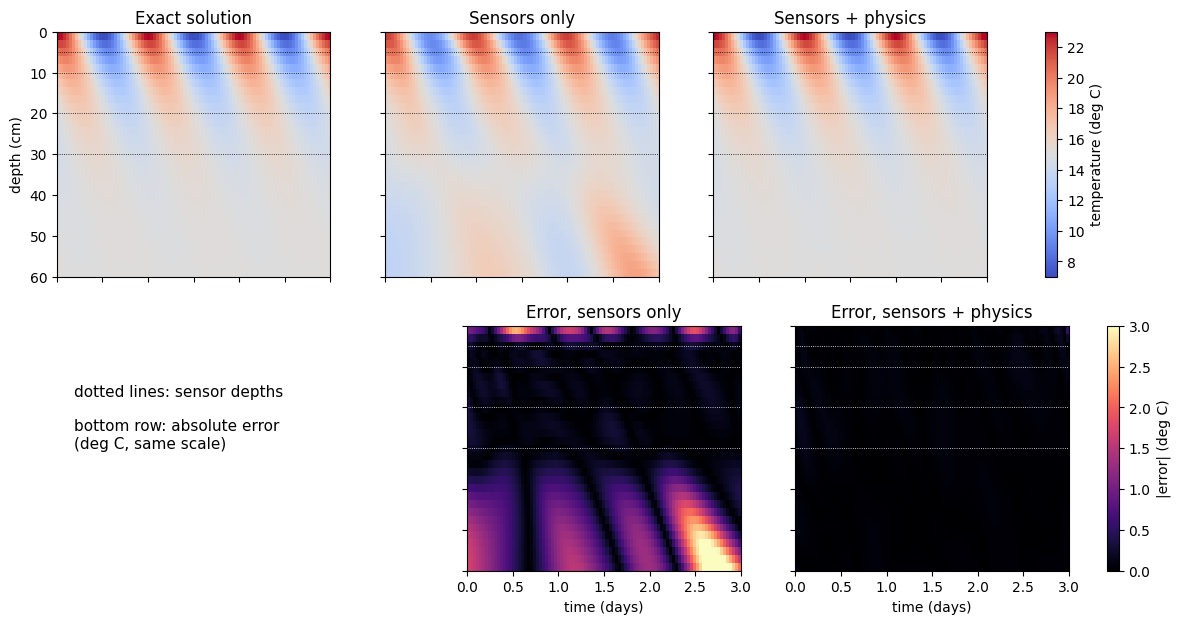

In [21]:
shape = (len(GRID_Z), len(GRID_T))
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
panels = [(axes[0, 0], GRID_EXACT, "Exact solution"), (axes[0, 1], field_data, "Sensors only"),
          (axes[0, 2], field_pinn, "Sensors + physics")]
for ax, field, title in panels:
    img = ax.imshow(to_celsius(np.asarray(field).reshape(shape)), aspect="auto", origin="upper", cmap="coolwarm",
                    vmin=T_MEAN - AMP, vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    for z in sensor_depths:
        ax.axhline(100 * z, color="k", lw=0.6, ls=":")
fig.colorbar(img, ax=axes[0, :], label="temperature (deg C)")
axes[1, 0].axis("off")
axes[1, 0].text(0.05, 0.5, "dotted lines: sensor depths\n\nbottom row: absolute error\n(deg C, same scale)",
                transform=axes[1, 0].transAxes, fontsize=11)
for ax, field, title in ((axes[1, 1], field_data, "Error, sensors only"), (axes[1, 2], field_pinn, "Error, sensors + physics")):
    err_img = ax.imshow(AMP * np.abs(np.asarray(field) - GRID_EXACT).reshape(shape), aspect="auto", origin="upper",
                        cmap="magma", vmin=0, vmax=3, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    for z in sensor_depths:
        ax.axhline(100 * z, color="w", lw=0.6, ls=":")
fig.colorbar(err_img, ax=axes[1, 1:], label="|error| (deg C)")
for ax in axes[1, 1:]:
    ax.set_xlabel("time (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("depth (cm)")
plt.show()

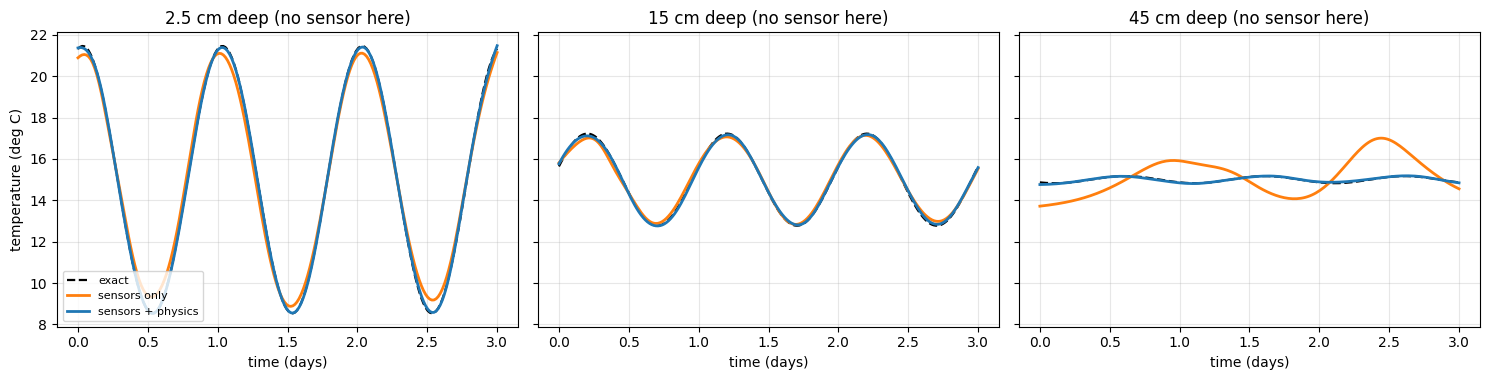

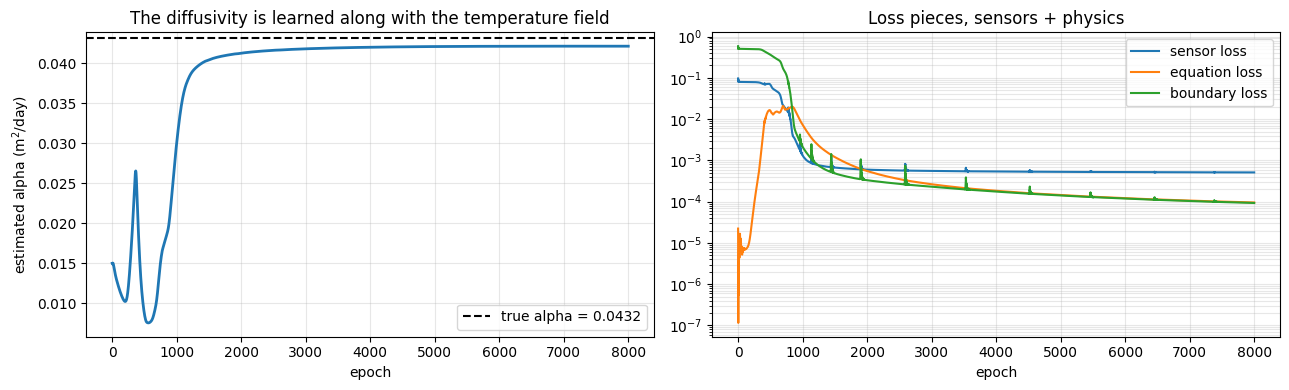

In [22]:
t_line = np.linspace(0, T_MAX, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, z_cm in zip(axes, (2.5, 15, 45)):
    X_line = np.column_stack([np.full_like(t_line, z_cm / 100.0), t_line]) / np.array([Z_MAX, T_MAX])
    ax.plot(t_line, to_celsius(exact_theta(z_cm / 100.0, t_line)), "k--", lw=1.6, label="exact")
    ax.plot(t_line, to_celsius(forward_jets(params_data, X_line)[0].ravel()), color="tab:orange", lw=2, label="sensors only")
    ax.plot(t_line, to_celsius(forward_jets(params_pinn, X_line)[0].ravel()), color="tab:blue", lw=2, label="sensors + physics")
    ax.set_title(f"{z_cm} cm deep (no sensor here)")
    ax.set_xlabel("time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("temperature (deg C)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(alpha_hist, lw=2)
axes[0].axhline(ALPHA_TRUE, color="k", ls="--", label=f"true alpha = {ALPHA_TRUE:.4f}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("estimated alpha (m$^2$/day)")
axes[0].set_title("The diffusivity is learned along with the temperature field")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].semilogy(hist_pinn[:, 1], label="sensor loss")
axes[1].semilogy(hist_pinn[:, 2], label="equation loss")
axes[1].semilogy(hist_pinn[:, 3], label="boundary loss")
axes[1].set_xlabel("epoch")
axes[1].set_title("Loss pieces, sensors + physics")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

**What to notice.**

* Between the sensors (5 to 30 cm), both networks follow the readings. The sensors-only network can do that because it has data there.
* Above the shallowest sensor and below the deepest one, the sensors-only network has nothing to go on. Its error there is about 0.8 °C above 5 cm and about 1 °C below 30 cm, and it grows to several degrees in the bottom corner of the map. The physics network is held to the equation and the boundary conditions over the whole map. Its error is only 0.03 to 0.06 °C in those same regions, **far below the 0.2 °C noise of a single reading**.
* The physics network starts with a diffusivity that is far too low and corrects it within the first couple of thousand epochs.

## A9. How does the network's estimate compare with the classical methods?
On the same readings, here are all four estimates side by side, and then the network's error placed on the histograms from Setup (300 repeats with new noise for the classical methods).

method                    alpha (m^2/day)    error
amplitude method                  0.04140    -4.2%
phase method                      0.04337     0.4%
formula fit                       0.04223    -2.2%
sensors + physics (network)          0.04213    -2.5%
truth                             0.04320


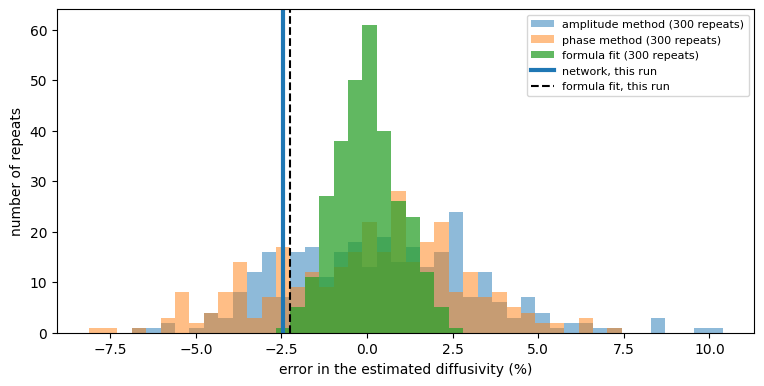

In [23]:
print(f"{'method':24s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase),
                    ("formula fit", alpha_fit), ("sensors + physics (network)", alpha_hat)):
    print(f"{name:24s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':24s}{ALPHA_TRUE:17.5f}")

plt.figure(figsize=(9, 4.2))
bins = np.linspace(error_pct.min(), error_pct.max(), 45)
plt.hist(error_pct[:, 0], bins=bins, alpha=0.5, label="amplitude method (300 repeats)")
plt.hist(error_pct[:, 1], bins=bins, alpha=0.5, label="phase method (300 repeats)")
plt.hist(error_pct[:, 2], bins=bins, alpha=0.75, label="formula fit (300 repeats)")
plt.axvline(100 * (alpha_hat / ALPHA_TRUE - 1), color="tab:blue", lw=3, label="network, this run")
plt.axvline(100 * (alpha_fit / ALPHA_TRUE - 1), color="k", lw=1.5, ls="--", label="formula fit, this run")
plt.xlabel("error in the estimated diffusivity (%)")
plt.ylabel("number of repeats")
plt.legend(fontsize=8)
plt.show()

**Reading this honestly.** On these readings the network lands almost exactly where the formula fit does. That is no accident: both use all the data together with the same physics, so both reach about the best answer that these readings allow. In this run the readings happen to point about 2% low (the formula fit says so too), which is within the normal wander of the repeats. The simple amplitude and phase methods are noisier.

So in this clean problem, **the network does not beat the best classical method, it matches it.** The reason to bother is what comes next: it needs no exact formula, so it keeps working when the formula does not apply.

## A10. A heat-budget check
Background section 7 gave a balance that every correct solution must obey: the rate of change of the stored heat, $\frac{d}{dt}\int_0^L\theta\,dz$, equals $\alpha\,[\theta_z(L,t)-\theta_z(0,t)]$. We compute both sides from each network (the depth integral by the trapezoid rule, the time derivative by finite differences, and $\theta_z$ at the two ends from the network's own derivative output) and check how well they agree. We use the true $\alpha$ for the sensors-only network (it has none of its own), and the learned $\alpha$ for the physics network. The check does not use the exact answer.

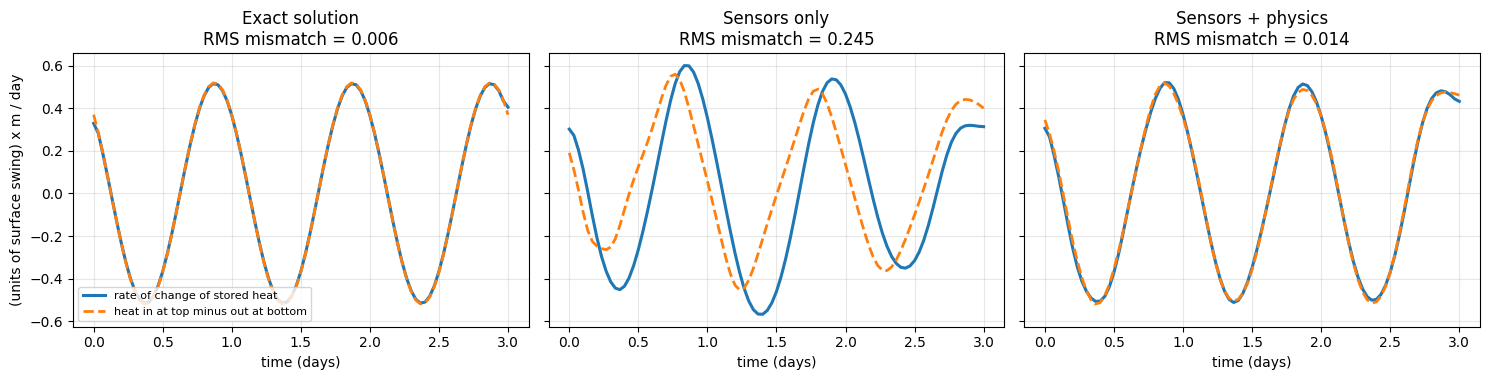

In [24]:
z_dense = np.linspace(0.0, Z_MAX, 241)

def trapezoid(y, x):
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))

def stored_heat_and_flux(params, alpha):
    # left side (rate of change of stored heat) and right side (heat in at top minus out at bottom)
    Q = np.array([trapezoid(forward_jets(params, np.column_stack([z_dense, np.full_like(z_dense, t)]) / np.array([Z_MAX, T_MAX]))[0].ravel(), z_dense)
                  for t in GRID_T])
    top = forward_jets(params, np.column_stack([np.zeros_like(GRID_T), GRID_T]) / np.array([Z_MAX, T_MAX]))[1].ravel()
    bottom = forward_jets(params, np.column_stack([np.full_like(GRID_T, Z_MAX), GRID_T]) / np.array([Z_MAX, T_MAX]))[1].ravel()
    return np.gradient(Q, GRID_T), alpha * (bottom - top)

def exact_budget():
    d = d_true
    def z_derivative(z, t):
        phi = OMEGA * t - z / d
        return np.exp(-z / d) / d * (np.sin(phi) - np.cos(phi))
    Q = np.array([trapezoid(exact_theta(z_dense, t), z_dense) for t in GRID_T])
    return np.gradient(Q, GRID_T), ALPHA_TRUE * (z_derivative(Z_MAX, GRID_T) - z_derivative(0.0, GRID_T))

left_exact, right_exact = exact_budget()
left_data, right_data = stored_heat_and_flux(params_data, ALPHA_TRUE)
left_pinn, right_pinn = stored_heat_and_flux(params_pinn, alpha_hat)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, (left, right, title) in zip(axes, ((left_exact, right_exact, "Exact solution"),
                                           (left_data, right_data, "Sensors only"),
                                           (left_pinn, right_pinn, "Sensors + physics"))):
    ax.plot(GRID_T, left, lw=2.2, label="rate of change of stored heat")
    ax.plot(GRID_T, right, "--", lw=2, label="heat in at top minus out at bottom")
    ax.set_title(f"{title}\nRMS mismatch = {np.sqrt(np.mean((left - right) ** 2)):.3f}")
    ax.set_xlabel("time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("(units of surface swing) x m / day")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

The exact solution balances to within the accuracy of the finite differences (RMS mismatch 0.006). The physics network balances almost as well (0.014). The sensors-only network is only constrained where the sensors are, so its two sides disagree by about 40 times more (0.245), with the wrong size and the wrong timing. You could run this check on any model of soil temperature without knowing the true answer.

## A11. The training video and GIF
Now the animation. Left: the sensors-only network. Right: the network with physics, which also has to find the diffusivity. For each there is:

1. the depth–time temperature map the network currently believes in (dotted lines mark the sensors),
2. the temperature against depth at day 2, with the exact curve and the sensor readings at that moment,
3. a strip with the error against the exact solution, and for the physics network the diffusivity estimate against the truth.

`make_training_video` writes a GIF (always works) and an MP4 (needs `ffmpeg`).

In [25]:
runs_video = [
    {"name": "Sensors only", "color": "tab:orange", "theta": snaps_data["theta"], "alpha": None, "rmse": snaps_data["rmse"]},
    {"name": "Sensors + physics", "color": "tab:blue", "theta": snaps_pinn["theta"], "alpha": snaps_pinn["alpha"], "rmse": snaps_pinn["rmse"]},
]
gif_path = MEDIA_DIR / "soil_heat_training.gif"
mp4_path = MEDIA_DIR / "soil_heat_training.mp4"

anim = make_training_video(snap_epochs, runs_video, mp4_path=mp4_path, gif_path=gif_path, fps=12)

saved GIF: media/soil_heat_training.gif  (1.9 MB)


saved MP4: media/soil_heat_training.mp4  (0.9 MB)


In [26]:
# optional: build a GIF from the MP4 with ffmpeg (a colour palette is computed for cleaner colours)
convert_mp4_to_gif(mp4_path, MEDIA_DIR / "soil_heat_training_from_mp4.gif", fps=12, width=800)

converted media/soil_heat_training.mp4 -> media/soil_heat_training_from_mp4.gif  (1.7 MB)


PosixPath('media/soil_heat_training_from_mp4.gif')

Here is the GIF. (In Jupyter it plays inline. Elsewhere, open the file in the `media` folder.)

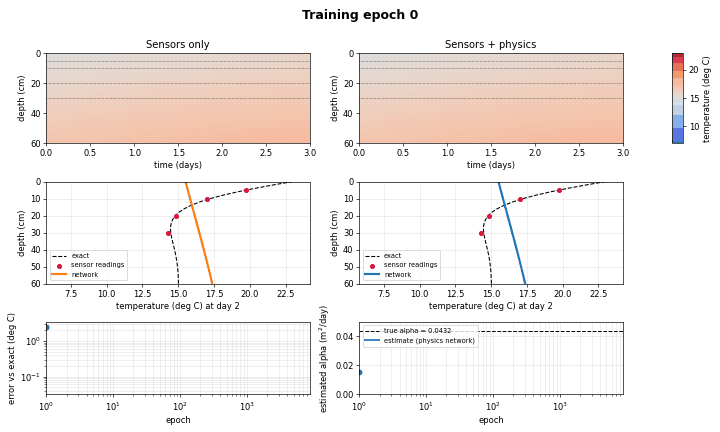

In [27]:
from IPython.display import Image, display
display(Image(filename=str(gif_path)))

A still picture of a few moments, for places where animations do not play:

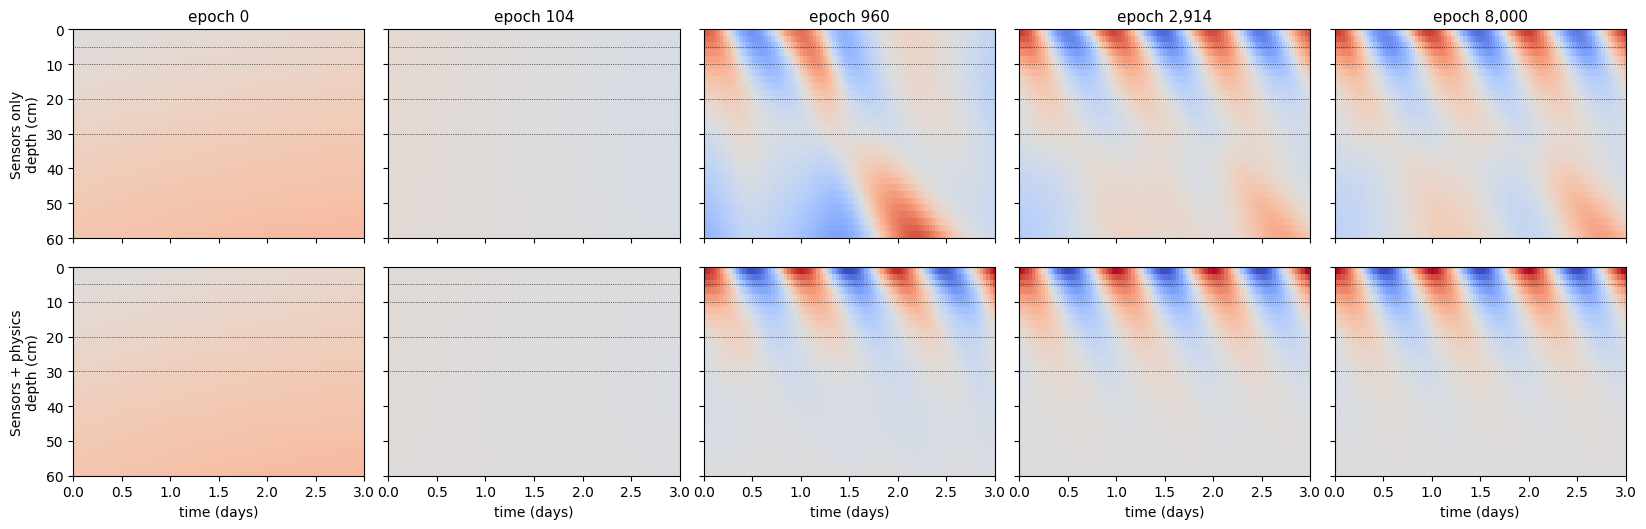

In [28]:
snapshot_grid(snap_epochs, runs_video, picks=(0, 100, 1000, 3000, 8000))

And a slider to move through training by hand (Jupyter or Colab):

In [29]:
scrub_epochs(snap_epochs, runs_video)

## A12. A harder test: a cloudy afternoon
*This section goes beyond the main experiment.*

So far the surface was a clean daily cosine, which has an exact solution. Real surfaces are messier. Here the surface temperature has a sharper afternoon peak (a second daily harmonic) and **a cloud that covers the sun for a couple of hours on day 2**, causing a sudden dip. There is no neat formula for this. The "truth" is computed with the Crank–Nicolson solver from Setup, starting from the soil's steady daily pattern. The four sensors read this truth with the same noise as before.

What changes for the methods?

* **Amplitude and phase methods** need a reference. We take the first daily harmonic of the **measured surface record** as the surface amplitude and phase.
* **A formula fit** is not possible. The classical way is to **fit with a solver**: try a diffusivity, run Crank–Nicolson, compare with the readings, and adjust. We do that too.
* **The network** needs no change at all, except that the surface record it is given is the messy one.

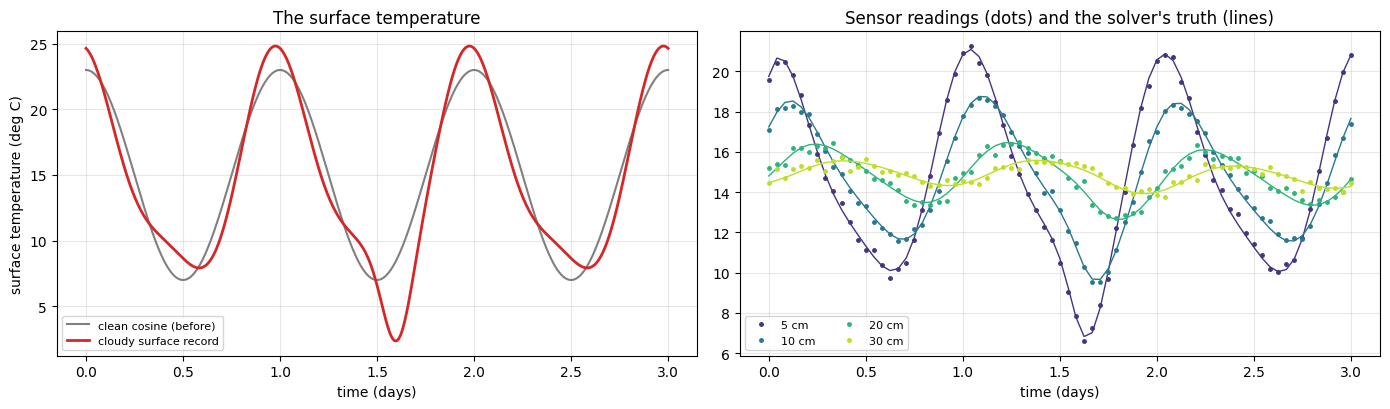

In [30]:
def surface_cloudy(t):
    # sharper afternoon peak (second harmonic) and a cloud dip on day 2
    return np.cos(OMEGA * t) + 0.25 * np.cos(2 * OMEGA * t + 0.6) - 0.7 * np.exp(-((t - 1.6) / 0.1) ** 2)


z_c, t_c, field_c = fd_solve(ALPHA_TRUE, surface_cloudy, Z_MAX, T_MAX, theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
truth_c = RegularGridInterpolator((t_c, z_c), field_c)

pts = np.array([(t, z) for z in sensor_depths for t in sensor_times])
theta_clean_c = truth_c(pts).reshape(len(sensor_depths), len(sensor_times))
theta_matrix_c = theta_clean_c + noise_theta * np.random.default_rng(5).standard_normal(theta_clean_c.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(t_fine, to_celsius(np.cos(OMEGA * t_fine)), color="gray", lw=1.5, label="clean cosine (before)")
axes[0].plot(t_fine, to_celsius(surface_cloudy(t_fine)), color="tab:red", lw=2, label="cloudy surface record")
axes[0].set_xlabel("time (days)")
axes[0].set_ylabel("surface temperature (deg C)")
axes[0].set_title("The surface temperature")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
for i, (z, colour) in enumerate(zip(sensor_depths, plt.cm.viridis(np.linspace(0.15, 0.9, 4)))):
    axes[1].plot(sensor_times, to_celsius(theta_matrix_c[i]), ".", color=colour, ms=5, label=f"{int(100*z)} cm")
    axes[1].plot(sensor_times, to_celsius(theta_clean_c[i]), "-", color=colour, lw=1)
axes[1].set_xlabel("time (days)")
axes[1].set_title("Sensor readings (dots) and the solver's truth (lines)")
axes[1].legend(ncol=2, fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# classical estimates for the cloudy case: amplitude and phase relative to the surface record's first harmonic
t_rec = np.arange(0.0, T_MAX + 1e-9, 1.0 / 96.0)
surface_rec = surface_cloudy(t_rec)
_surface_coef = np.linalg.lstsq(np.column_stack([np.ones_like(t_rec), np.cos(OMEGA * t_rec), np.sin(OMEGA * t_rec)]),
                                surface_rec, rcond=None)[0]
surface_amp, surface_phase = np.hypot(_surface_coef[1], _surface_coef[2]), np.arctan2(_surface_coef[2], _surface_coef[1])

def classical_alphas_cloudy(theta_by_depth):
    amplitude, phase = amplitude_and_phase(theta_by_depth)
    ln_ratio = np.log(amplitude / surface_amp)
    delay = (phase - surface_phase + np.pi) % (2 * np.pi) - np.pi
    d_amp = -np.sum(sensor_depths**2) / np.sum(sensor_depths * ln_ratio)
    d_phase = np.sum(sensor_depths**2) / np.sum(sensor_depths * delay)
    return OMEGA * d_amp**2 / 2.0, OMEGA * d_phase**2 / 2.0

def solver_fit_alpha(theta_by_depth):
    # fit alpha by running the classical solver for each trial value
    def misfit(a):
        z_t, t_t, f_t = fd_solve(a, surface_cloudy, Z_MAX, T_MAX, dz=0.005, dt=0.004,
                                 theta0=lambda z: exact_theta(z, 0.0), deep=0.0)
        interp = RegularGridInterpolator((t_t, z_t), f_t)
        return np.sum((theta_by_depth - interp(pts).reshape(theta_by_depth.shape)) ** 2)
    return minimize_scalar(misfit, bounds=(0.02, 0.08), method="bounded", options={"xatol": 1e-6}).x

alpha_amp_c, alpha_phase_c = classical_alphas_cloudy(theta_matrix_c)
alpha_solver_c = solver_fit_alpha(theta_matrix_c)

# 300 repeats of the harmonic methods with new noise
rng_c = np.random.default_rng(7)
rep_c = np.array([classical_alphas_cloudy(theta_clean_c + noise_theta * rng_c.standard_normal(theta_clean_c.shape))
                  for _ in range(300)])
err_c = 100 * (rep_c / ALPHA_TRUE - 1)
print(f"on perfectly clean readings, amplitude / phase method: {classical_alphas_cloudy(theta_clean_c)[0]:.4f} / "
      f"{classical_alphas_cloudy(theta_clean_c)[1]:.4f}   (truth {ALPHA_TRUE:.4f})")
print(f"over 300 noisy repeats: amplitude method mean {err_c[:,0].mean():.2f}% spread {err_c[:,0].std():.2f}%;  "
      f"phase method mean {err_c[:,1].mean():.2f}% spread {err_c[:,1].std():.2f}%")

on perfectly clean readings, amplitude / phase method: 0.0429 / 0.0438   (truth 0.0432)
over 300 noisy repeats: amplitude method mean -0.40% spread 2.59%;  phase method mean 1.29% spread 2.63%


In [32]:
batch_c = build_batch(theta_sensors=theta_matrix_c.reshape(-1, 1), surface_function=surface_cloudy, n_boundary=300)
params_c, hist_c, alpha_hist_c, _ = train((1.0, 1.0, 1.0), learn_alpha=True, batch=batch_c, verbose=False)
alpha_hat_c = alpha_hist_c[-1]

ex_c = truth_c(np.column_stack([GRID_POINTS[:, 1], GRID_POINTS[:, 0]]))
field_c_net = forward_jets(params_c, GRID_X)[0].ravel()
print(f"{'method':32s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp_c), ("phase method", alpha_phase_c),
                    ("fit with the classical solver", alpha_solver_c), ("sensors + physics (network)", alpha_hat_c)):
    print(f"{name:32s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")
print(f"{'truth':32s}{ALPHA_TRUE:17.5f}")
print(f"\nnetwork temperature map: RMSE against the solver's truth = {AMP*rmse(field_c_net, ex_c):.3f} deg C")

method                            alpha (m^2/day)    error
amplitude method                          0.04121    -4.6%
phase method                              0.04387     1.6%
fit with the classical solver             0.04262    -1.4%
sensors + physics (network)               0.04222    -2.3%
truth                                     0.04320

network temperature map: RMSE against the solver's truth = 0.059 deg C


**What this shows.** The network recovers the diffusivity from the messy surface record (2.3% low) about as well as the classical solver fit does (1.4% low), with a single training run and no exact formula. Its temperature map matches the solver's to about 0.06 °C. The harmonic methods still work here too, because a two-hour cloud is a small disturbance to the daily wave: on clean readings they are off by only a percent or so. Their remaining problem is the noise, with the typical wander shown above.

So the honest summary is not "the network wins". It is that **the network handles the messy case with the same code and no special treatment**, while giving results comparable to the best classical approach, which here needs a solver to be run again and again.

**End of Part A.** Everything above used NumPy only: a network that returns its own time and depth derivatives, hand-derived gradients tested against finite differences, an optimiser, an inverse problem, a heat-budget check, a training video, and a messy-surface test. In Part B the derivative work is done by PyTorch.

---
---
# Part B: PyTorch and more advanced tools

The experiment is the same as in Part A: the same soil, the same four sensors, the same surface record, the same network shape and the same training schedule. What changes is who does the calculus.

1. **Automatic differentiation** gives $\hat\theta_t$, $\hat\theta_z$ and $\hat\theta_{zz}$. We call PyTorch's `autograd.grad` and never write the layer-by-layer formulas of background section 10.
2. **Backpropagation** for the whole loss, including both derivatives and the unknown diffusivity, is one call to `loss.backward()`. The long derivation of A3 collapses into a single line.

The first half (B1 to B8) rebuilds the experiment and the video in PyTorch. The second half (B9 to B11) adds L-BFGS polishing, the functional `torch.func` interface, and a study of **how many sensors you need**.

> **Setup needed.** Part B needs PyTorch (`pip install torch`; Colab has it). Run the **Setup** section first: the constants, sensor readings, classical estimators and helper functions come from there.
>
> **Runtime.** Differentiating twice through a network at 1500 points is slower than a plain forward pass. As a rough guide, the whole of Part B takes somewhere around 15 to 25 minutes on a laptop CPU.
>
> **Random numbers.** PyTorch draws different random numbers from NumPy, so the starting weights differ from Part A. Expect results close to, but not identical with, Part A.

## B1. Imports and random seed

In [ ]:
import copy
import torch
import torch.nn as nn

torch.manual_seed(0)

## B2. Tensors
The sensor readings, the surface record, the collocation points and the evaluation grid from Setup and Part A, as `float32` tensors with one row per point. Depth and time are kept as separate columns, because we will differentiate with respect to each one separately.

In [ ]:
def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)

# sensor readings
z_m_t, t_m_t, theta_m_t = to_tensor(zt_data[:, 0:1]), to_tensor(zt_data[:, 1:2]), to_tensor(theta_data)

# surface (z = 0) and deep (z = Z_MAX) boundary points
t_edge = np.linspace(0.0, T_MAX, 150).reshape(-1, 1)
t_s_t = to_tensor(t_edge)
z_s_t = torch.zeros_like(t_s_t)
theta_s_t = torch.cos(OMEGA * t_s_t)                  # the surface record: a clean daily cosine
z_d_t = torch.full_like(t_s_t, Z_MAX)
t_d_t = t_s_t.clone()

# 1500 random points over the whole depth-time rectangle, where the equation is checked
gen = torch.Generator().manual_seed(1)
z_c_t = torch.rand(1500, 1, generator=gen) * Z_MAX
t_c_t = torch.rand(1500, 1, generator=gen) * T_MAX

# evaluation grid
grid_z_t, grid_t_t = to_tensor(GRID_POINTS[:, 0:1]), to_tensor(GRID_POINTS[:, 1:2])
print(z_m_t.shape, z_c_t.shape, grid_z_t.shape)

## B3. The network
A fully connected network, 2 → 24 → 24 → 24 → 1 with $\tanh$, Xavier-uniform weights and zero biases. Its `forward` method takes depth and time as two separate columns, scales them (dividing by `Z_MAX` and `T_MAX`) and joins them into the two inputs. Because the scaling is *inside* the network, derivatives taken with respect to the physical depth and time come out right automatically.

In [ ]:
class HeatPINN(nn.Module):
    def __init__(self, hidden=(24, 24, 24)):
        super().__init__()
        sizes = [2, *hidden, 1]
        layers = []
        for i in range(len(sizes) - 1):
            linear = nn.Linear(sizes[i], sizes[i + 1])
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)
            layers.append(linear)
            if i < len(sizes) - 2:
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)

    def forward(self, z, t):
        # z, t: columns of shape (N, 1), in physical units
        return self.net(torch.cat([z / Z_MAX, t / T_MAX], dim=1))

## B4. Differentiating with autograd
`torch.autograd.grad(y, x, ...)` returns $\partial y/\partial x$ for every entry. We call it three times: for $\hat\theta_t$, for $\hat\theta_z$, and again on $\hat\theta_z$ to get $\hat\theta_{zz}$. As before, `create_graph=True` keeps the record needed to differentiate again and to differentiate the loss with respect to the weights. The residual is scaled by $\omega$ exactly as in background section 9.

In [ ]:
def grad(y, x):
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]


def pde_residual(model, z, t, alpha):
    z = z.clone().requires_grad_(True)
    t = t.clone().requires_grad_(True)
    theta = model(z, t)
    theta_t = grad(theta, t)             # rate of change in time
    theta_z = grad(theta, z)             # slope in depth
    theta_zz = grad(theta_z, z)          # curvature in depth
    return (theta_t - alpha * theta_zz) / OMEGA

## B5. The loss pieces
The same three pieces as in Part A: the sensors, the equation at the collocation points, and the boundaries (surface record on top, steady deep value at the bottom). The function can be given a different set of sensor readings, which we use in B11.

In [ ]:
def heat_losses(model, alpha, data=None):
    z_m, t_m, th_m = (z_m_t, t_m_t, theta_m_t) if data is None else data
    l_data = torch.mean((model(z_m, t_m) - th_m) ** 2)
    l_pde = torch.mean(pde_residual(model, z_c_t, t_c_t, alpha) ** 2)
    l_bc = torch.mean((model(z_s_t, t_s_t) - theta_s_t) ** 2) + torch.mean(model(z_d_t, t_d_t) ** 2)
    return l_data, l_pde, l_bc

## B6. Training
As in Part A, one function trains either network: `lam = (lam_data, lam_bc, lam_pde)`, so `(1, 0, 0)` is the sensors-only network and `(1, 1, 1)` with `learn_alpha=True` is the physics network. The diffusivity is held as its **logarithm** in an `nn.Parameter`, so it stays positive and autograd works out its gradient on its own. In A3 we derived that gradient by hand, and it is the same quantity. The learning rate falls from $3\times10^{-3}$ to $10^{-4}$ with `ExponentialLR`.

In [ ]:
EPOCHS = 8000
LR_START, LR_END = 3e-3, 1e-4


def train_torch(lam, epochs=EPOCHS, learn_alpha=False, alpha_start=0.015, seed=0, data=None,
                snapshot_epochs=None, verbose=True, print_every=1000):
    torch.manual_seed(seed)
    model = HeatPINN()
    params = list(model.parameters())
    log_alpha = None
    if learn_alpha:
        log_alpha = nn.Parameter(torch.log(torch.tensor(float(alpha_start))))
        params.append(log_alpha)
    optimizer = torch.optim.Adam(params, lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, alpha_history = [], []
    snap_theta, snap_alpha, snap_rmse = [], [], []
    for epoch in range(epochs + 1):
        alpha_value = torch.exp(log_alpha) if learn_alpha else ALPHA_TRUE
        alpha_now = alpha_value.item() if learn_alpha else ALPHA_TRUE
        if epoch in snap_set:
            with torch.no_grad():
                field = model(grid_z_t, grid_t_t).numpy().ravel()
            snap_theta.append(field.copy())
            snap_alpha.append(alpha_now)
            snap_rmse.append(AMP * rmse(field, GRID_EXACT))
        if epoch == epochs:
            break
        optimizer.zero_grad()
        z_m, t_m, th_m = (z_m_t, t_m_t, theta_m_t) if data is None else data
        l_data = torch.mean((model(z_m, t_m) - th_m) ** 2)
        l_pde = torch.mean(pde_residual(model, z_c_t, t_c_t, alpha_value) ** 2) if lam[2] > 0 else torch.zeros(())
        l_bc = (torch.mean((model(z_s_t, t_s_t) - theta_s_t) ** 2) + torch.mean(model(z_d_t, t_d_t) ** 2)
                if lam[1] > 0 else torch.zeros(()))
        total = lam[0] * l_data + lam[1] * l_bc + lam[2] * l_pde
        total.backward()
        optimizer.step()
        scheduler.step()
        history.append([total.item(), l_data.item(), l_pde.item(), l_bc.item()])
        alpha_history.append(alpha_now)
        if verbose and (epoch + 1) % print_every == 0:
            extra = f"  alpha = {alpha_now:.5f}" if learn_alpha else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.3e}  sensors = {l_data.item():.2e}  "
                  f"equation = {l_pde.item():.2e}  boundary = {l_bc.item():.2e}{extra}")
    snaps = {"theta": np.array(snap_theta), "alpha": np.array(snap_alpha) if learn_alpha else None,
             "rmse": np.array(snap_rmse)}
    return model, log_alpha, np.array(history), np.array(alpha_history), snaps


def predict_grid(model):
    with torch.no_grad():
        return model(grid_z_t, grid_t_t).numpy().ravel()

## B7. Train both networks and compare
The same recipe as A7: a sensors-only network and a physics network that has to find $\alpha$ from a wrong starting guess of 0.015. The error table splits the depth range as in A8.

In [ ]:
snap_epochs = make_snapshot_epochs(EPOCHS)

print("=== sensors only ===")
model_data, _, hist_data_t, _, snaps_data_t = train_torch((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== sensors + physics, diffusivity unknown ===")
model_pinn, log_alpha_pinn, hist_pinn_t, alpha_hist_t, snaps_pinn_t = train_torch(
    (1.0, 1.0, 1.0), learn_alpha=True, snapshot_epochs=snap_epochs)
alpha_hat_t = alpha_hist_t[-1]

In [ ]:
def field_errors_torch(theta_flat):
    shape = (len(GRID_Z), len(GRID_T))
    err = AMP * (np.asarray(theta_flat).reshape(shape) - GRID_EXACT.reshape(shape))
    band = (GRID_Z >= 0.05) & (GRID_Z <= 0.30)
    return {"sensor depths (5-30 cm)": np.sqrt(np.mean(err[band] ** 2)),
            "above 5 cm": np.sqrt(np.mean(err[GRID_Z < 0.05] ** 2)),
            "below 30 cm": np.sqrt(np.mean(err[GRID_Z > 0.30] ** 2)),
            "whole map": np.sqrt(np.mean(err ** 2))}

e_data_t = field_errors_torch(predict_grid(model_data))
e_pinn_t = field_errors_torch(predict_grid(model_pinn))
print(f"{'error vs exact (deg C)':28s}{'sensors only':>14s}{'sensors + physics':>19s}")
print(f"{'sensor noise (for reference)':28s}{noise_celsius:14.2f}{noise_celsius:19.2f}")
for key in e_data_t:
    print(f"{key:28s}{e_data_t[key]:14.3f}{e_pinn_t[key]:19.3f}")
print(f"\nestimated diffusivity: {alpha_hat_t:.5f} m^2/day   (true {ALPHA_TRUE:.5f}, error {100*(alpha_hat_t/ALPHA_TRUE-1):.1f}%)")

print(f"\n{'method':28s}{'alpha (m^2/day)':>17s}{'error':>9s}")
for name, value in (("amplitude method", alpha_amp), ("phase method", alpha_phase),
                    ("formula fit", alpha_fit), ("sensors + physics (PyTorch)", alpha_hat_t)):
    print(f"{name:28s}{value:17.5f}{100*(value/ALPHA_TRUE-1):8.1f}%")

shape = (len(GRID_Z), len(GRID_T))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, field, title in ((axes[0], GRID_EXACT, "Exact solution"), (axes[1], predict_grid(model_data), "Sensors only"),
                         (axes[2], predict_grid(model_pinn), "Sensors + physics (PyTorch)")):
    img = ax.imshow(to_celsius(np.asarray(field).reshape(shape)), aspect="auto", origin="upper", cmap="coolwarm",
                    vmin=T_MEAN - AMP, vmax=T_MEAN + AMP, extent=[0, T_MAX, 100 * Z_MAX, 0])
    ax.set_title(title)
    ax.set_xlabel("time (days)")
    for z in sensor_depths:
        ax.axhline(100 * z, color="k", lw=0.6, ls=":")
axes[0].set_ylabel("depth (cm)")
fig.colorbar(img, ax=axes, label="temperature (deg C)")
plt.show()

The pattern to look for is the one from Part A: both networks follow the readings between the sensors, the sensors-only network goes wrong above the first sensor and below the last, and the physics network stays close to the truth everywhere and finds a diffusivity close to the true value. The exact numbers differ a little from Part A, because the starting weights are different and PyTorch works in 32-bit numbers where our NumPy code used 64-bit ones.

## B8. The training video again, from the PyTorch run
The same helper builds the animation. The files get a `_pytorch` suffix.

In [ ]:
runs_video_t = [
    {"name": "Sensors only", "color": "tab:orange", "theta": snaps_data_t["theta"], "alpha": None, "rmse": snaps_data_t["rmse"]},
    {"name": "Sensors + physics", "color": "tab:blue", "theta": snaps_pinn_t["theta"], "alpha": snaps_pinn_t["alpha"], "rmse": snaps_pinn_t["rmse"]},
]
gif_path_t = MEDIA_DIR / "soil_heat_training_pytorch.gif"
mp4_path_t = MEDIA_DIR / "soil_heat_training_pytorch.mp4"

anim_t = make_training_video(snap_epochs, runs_video_t, mp4_path=mp4_path_t, gif_path=gif_path_t, fps=12)

from IPython.display import Image, display
display(Image(filename=str(gif_path_t)))

In [ ]:
snapshot_grid(snap_epochs, runs_video_t, picks=(0, 100, 1000, 3000, 8000))

In [ ]:
scrub_epochs(snap_epochs, runs_video_t)

---
## Advanced additions

Everything below goes beyond the basic experiment.

## B9. Polishing with L-BFGS
Adam is steady but slow to settle. **L-BFGS** builds a rough picture of how the loss curves from the last several gradients and takes larger, better-aimed steps (Liu and Nocedal, 1989). A common recipe is Adam first and L-BFGS to finish. Here it polishes both the network weights and the diffusivity together.

PyTorch's L-BFGS needs a **closure**, a function that recomputes the loss and its gradients on demand. It prefers 64-bit numbers, and our model is 32-bit, so progress can stall or occasionally give non-finite values. The cell checks for that and keeps the Adam result if it happens. We run at most 200 iterations to keep the time reasonable.

In [ ]:
model_lbfgs = copy.deepcopy(model_pinn)
log_alpha_lbfgs = nn.Parameter(log_alpha_pinn.detach().clone())
lbfgs = torch.optim.LBFGS(list(model_lbfgs.parameters()) + [log_alpha_lbfgs], lr=1.0, max_iter=200,
                          history_size=50, tolerance_grad=1e-12, tolerance_change=1e-15,
                          line_search_fn="strong_wolfe")

def closure():
    lbfgs.zero_grad()
    l_data, l_pde, l_bc = heat_losses(model_lbfgs, torch.exp(log_alpha_lbfgs))
    loss = l_data + l_pde + l_bc
    loss.backward()
    return loss

before_err = field_errors_torch(predict_grid(model_pinn))["whole map"]
before_alpha = torch.exp(log_alpha_pinn).item()
lbfgs.step(closure)
after_field = predict_grid(model_lbfgs)

if np.isfinite(after_field).all():
    print(f"whole-map error  before L-BFGS: {before_err:.4f} deg C   after: {field_errors_torch(after_field)['whole map']:.4f} deg C")
    print(f"alpha estimate   before L-BFGS: {before_alpha:.5f}   after: {torch.exp(log_alpha_lbfgs).item():.5f}   (true {ALPHA_TRUE:.5f})")
else:
    print("L-BFGS produced non-finite values in 32-bit arithmetic; keeping the Adam result.")

Do not expect a dramatic change. The readings are noisy, so the limit on the diffusivity estimate is the noise in the data and not the optimiser. L-BFGS helps more when the data are clean or when you solve an equation with no data at all (as in the Blasius notebook).

## B10. Derivatives with `torch.func`
In B4 we called `autograd.grad` three times. The functional interface `torch.func` works differently: write a function for a **single** point, then ask for its derivatives. `jacrev(f, argnums=1)` differentiates with respect to the second argument (time), and `jacrev(jacrev(f, argnums=0), argnums=0)` differentiates twice with respect to the first (depth). `vmap` applies the result to a whole batch. This style is common in more advanced code, and it extends cleanly to several inputs and mixed derivatives. Below, the time-derivative and second depth-derivative of the trained network are computed both ways and compared.

In [ ]:
from torch.func import vmap, jacrev

def theta_scalar(z, t):
    # network output for one point: scalars in, scalar out
    return model_pinn(z.reshape(1, 1), t.reshape(1, 1)).reshape(())

d_dt = vmap(jacrev(theta_scalar, argnums=1))
d2_dz2 = vmap(jacrev(jacrev(theta_scalar, argnums=0), argnums=0))

z_chk = torch.linspace(0.02, 0.55, 9)
t_chk = torch.linspace(0.1, 2.9, 9)
theta_t_func, theta_zz_func = d_dt(z_chk, t_chk), d2_dz2(z_chk, t_chk)

z_ag = z_chk.reshape(-1, 1).clone().requires_grad_(True)
t_ag = t_chk.reshape(-1, 1).clone().requires_grad_(True)
theta_ag = model_pinn(z_ag, t_ag)
theta_t_ag = grad(theta_ag, t_ag)
theta_zz_ag = grad(grad(theta_ag, z_ag), z_ag)

print("largest difference in theta_t: ", float((theta_t_func - theta_t_ag.reshape(-1)).abs().max()))
print("largest difference in theta_zz:", float((theta_zz_func - theta_zz_ag.reshape(-1)).abs().max()))

The two interfaces agree up to rounding.

## B11. How many sensors do you need?
The most practical question for anyone who wants to bury sensors. We train the physics network, with the diffusivity unknown, using **different subsets** of the sensors: only the 10 cm sensor, the 5 and 10 cm pair, and all four. Each run is 5000 epochs, shorter than the main run to keep the time reasonable, so the numbers are not directly comparable with B7. Where the classical amplitude and phase methods can be applied to the same subset, we show them too.

In [ ]:
def sensor_subset(depths_cm):
    keep = np.isin(np.round(100 * zt_data[:, 0]).astype(int), depths_cm)
    return (to_tensor(zt_data[keep, 0:1]), to_tensor(zt_data[keep, 1:2]), to_tensor(theta_data[keep]))

configs = [((10,), "10 cm only"), ((5, 10), "5 and 10 cm"), ((5, 10, 20, 30), "all four")]
study = []
for depths_cm, label in configs:
    model_s, _, _, alpha_hist_s, _ = train_torch((1.0, 1.0, 1.0), epochs=5000, learn_alpha=True,
                                                 data=sensor_subset(depths_cm), verbose=False)
    rows = [np.where(np.isclose(sensor_depths, c / 100.0))[0][0] for c in depths_cm]
    a_amp, a_phase = classical_alphas(theta_matrix[rows], depths=sensor_depths[rows])
    study.append((label, alpha_hist_s[-1], a_amp, a_phase, field_errors_torch(predict_grid(model_s))["whole map"]))

print(f"{'sensors':14s}{'network':>10s}{'amplitude':>11s}{'phase':>9s}{'map error (deg C)':>20s}      (true alpha = {ALPHA_TRUE:.4f})")
for label, a_net, a_amp, a_phase, err in study:
    print(f"{label:14s}{a_net:10.4f}{a_amp:11.4f}{a_phase:9.4f}{err:20.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(study))
ax.bar(positions - 0.27, [100 * (s[1] / ALPHA_TRUE - 1) for s in study], width=0.27, label="network")
ax.bar(positions, [100 * (s[2] / ALPHA_TRUE - 1) for s in study], width=0.27, label="amplitude method")
ax.bar(positions + 0.27, [100 * (s[3] / ALPHA_TRUE - 1) for s in study], width=0.27, label="phase method")
ax.axhline(0, color="k", lw=1)
ax.set_xticks(positions)
ax.set_xticklabels([s[0] for s in study])
ax.set_ylabel("error in the diffusivity (%)")
ax.set_title("Diffusivity error against the number of sensors (one noise sample)")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.show()

This is one noise sample for each setting, so it cannot show a trend by itself. A fair study would repeat each setting with many noise draws, as in Setup S8. Still, it shows that the physics network can work with very few sensors, because the surface record and the heat equation supply the rest. The map error (last column) is the more telling number: how well the whole temperature field is reproduced with so little data.

---
# Summary

| | Part A (NumPy) | Part B (PyTorch) |
|---|---|---|
| Time and depth derivatives of the network | Written by hand, layer by layer, in two directions | `torch.autograd.grad`, or `torch.func` |
| Gradient of the loss | Derived by hand, tested against finite differences | `loss.backward()` |
| Unknown diffusivity | Gradient for $\log\alpha$ derived and coded by hand | `nn.Parameter` and autograd |
| Optimiser | Adam from its equations, decaying step size | `torch.optim.Adam` with `ExponentialLR`, then `LBFGS` |
| Beyond the main test | A heat-budget check and a cloudy-surface test | A study of how many sensors are needed |
| Good for | Understanding every step | Faster experiments, other optimisers, larger models |

**What the experiments showed**

* The daily temperature wave in soil is a **damped, delayed wave**, $e^{-z/d}\cos(\omega t-z/d)$ with $d=\sqrt{2\alpha/\omega}$. The same decaying-cosine shape as the damped oscillator, spread over depth. We derived it, and checked it against an independent classical solver.
* The diffusivity can be read from the **amplitude** and the **delay** of the daily swing at several depths. That is the classical method, and it works, but each estimate wanders by a few percent when sensors have realistic noise.
* A network trained on the sensor readings alone is wrong where there are no sensors (above the first and below the last). A network that also knows the heat equation and the surface temperature gets the **whole depth–time map** right, to within a few hundredths of a degree, and finds the diffusivity at the same time.
* On clean daily-cosine data, the network **matches** the best classical estimate (fitting the exact formula) but does not beat it. Its advantage is that it needs no exact formula: with a messy surface record containing a cloud dip, it worked with the same code.
* A conservation law, the **heat budget**, lets us test a temperature model without knowing the true answer.

**Limits of this example**

* **The soil is uniform and conduction is the only way heat moves.** Real soil changes with depth and with moisture, and water moving through it carries heat too. A single diffusivity is then only an "apparent" value, and the amplitude and phase methods will often disagree. The network inherits the same assumption.
* **The surface temperature is known.** We gave the network the surface record. If it is unknown, more sensors are needed.
* **The deep boundary is an approximation.** We hold the temperature at 0.6 m constant, which costs a few hundredths of a degree.
* **One noise sample** was used for the networks. The repeat test in Setup S8 covers only the classical methods. A careful study would repeat the network runs too.
* **A classical solver is quicker** for the heat equation when everything is known. The network is worth it when data and physics must be combined, when constants are unknown, or when conditions are messy.

**Design choices that are ours, not part of the physics**

| Choice | Why |
|---|---|
| Temperature anomaly in units of the surface swing; residual divided by $\omega$ | Puts all loss terms on the scale of one, so the weights can stay near 1 |
| Network inputs scaled by $L$ and $t_{\max}$ (the chain rule is built into the derivative seeds) | Keeps the numbers the network sees of order one |
| Train $\log\alpha$, starting at 0.015 | Keeps the diffusivity positive; the start is deliberately wrong |
| No initial-condition term | The starting profile is unknown, and the sensors and equation settle it |
| 1500 random collocation points, fixed | Enough to hold the field together over the whole rectangle |
| 8000 epochs, learning rate $3\times10^{-3}\to10^{-4}$ | A fixed rate jitters late in training |
| Sensors at 5, 10, 20, 30 cm, hourly, 0.2 °C noise | A realistic buried-probe set-up |

**Things to try**

* Raise the noise (`noise_celsius` in S7), or use fewer readings, and watch the estimates spread.
* Move the sensors deeper (for example 20, 30, 40 cm) and see how the amplitude method suffers first.
* Make the cycle **yearly** instead of daily. The damping depth grows by $\sqrt{365}\approx19$ times, to about 2 m, so you would need deep probes and a domain several metres deep.
* Try the **heat-shield case** of background section 6: sudden surface heating, thermocouples at a few depths, and the diffusivity as the unknown. The early-time gradients are steep, which makes it a harder test.
* Use **two layers** of soil with different diffusivities and see what the amplitude and phase methods report, then try a network with a diffusivity that depends on depth.
* Give the network the wrong surface record (shifted by an hour) and watch the error propagate to $\alpha$.

# References

1. H. S. Carslaw, J. C. Jaeger, *Conduction of Heat in Solids*, 2nd edition, Oxford University Press (1959).
2. F. P. Incropera, D. P. DeWitt, T. L. Bergman, A. S. Lavine, *Fundamentals of Heat and Mass Transfer*, 7th edition, Wiley (2011).
3. D. Hillel, *Environmental Soil Physics*, Academic Press (1998).
4. R. Horton, P. J. Wierenga, D. R. Nielsen, *Evaluation of methods for determining the apparent thermal diffusivity of soil near the surface*, Soil Science Society of America Journal, 47(1), 25–32 (1983).
5. J. C. Price, *Thermal inertia mapping: A new view of the Earth*, Journal of Geophysical Research, 82(18), 2582–2590 (1977).
6. J. Crank, P. Nicolson, *A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type*, Proceedings of the Cambridge Philosophical Society, 43(1), 50–67 (1947).
7. M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics, 378, 686–707 (2019).
8. S. Cuomo, V. S. Di Cola, F. Giampaolo, G. Rozza, M. Raissi, F. Piccialli, *Scientific machine learning through physics-informed neural networks: Where we are and what's next*, Journal of Scientific Computing, 92, 88 (2022).
9. D. P. Kingma, J. Ba, *Adam: A method for stochastic optimization*, ICLR (2015).
10. X. Glorot, Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks*, AISTATS, 249–256 (2010).
11. D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Mathematical Programming, 45, 503–528 (1989).
12. A. G. Baydin, B. A. Pearlmutter, A. A. Radul, J. M. Siskind, *Automatic differentiation in machine learning: a survey*, Journal of Machine Learning Research, 18(153), 1–43 (2018).
13. S. Wang, S. Sankaran, P. Perdikaris, *Respecting causality is all you need for training physics-informed neural networks*, arXiv:2203.07404 (2022).
14. A. Krishnapriyan, A. Gholami, S. Zhe, R. Kirby, M. W. Mahoney, *Characterizing possible failure modes in physics-informed neural networks*, Advances in Neural Information Processing Systems 34 (2021).